In [1]:

import numpy as np 
import pandas as pd 


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub


/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_GroundTruth.csv
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Supplement.csv
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Test_Metadata.csv
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Metadata.csv
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/attribution.txt
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_0382638/ISIC_3204703.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_0382638/ISIC_6467926.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_8931844/ISIC_8253140.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_8931844/ISIC_0373682.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_1891015/ISIC_6221926.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_1891015/ISIC_1143783.jpg
/kaggl

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for file in files[:10]:
        print("   ", file)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/able23
/kaggle/input/datasets/able23/skincancermilk10k
    MILK10k_Training_GroundTruth.csv
    MILK10k_Training_Supplement.csv
    MILK10k_Test_Metadata.csv
    MILK10k_Training_Metadata.csv
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input
    attribution.txt
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_0382638
    ISIC_3204703.jpg
    ISIC_6467926.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_8931844
    ISIC_8253140.jpg
    ISIC_0373682.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_1891015
    ISIC_6221926.jpg
    ISIC_1143783.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_8500079
    ISIC_3042149.jpg
    ISIC_5772488.jpg
/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_0076523
    ISIC_6171480.jpg
    ISIC_3175480.jpg
/kaggle/input/datasets/able23/skincan

# Load the training metadata

In [3]:
import pandas as pd

BASE_PATH = "/kaggle/input/datasets/able23/skincancermilk10k"

metadata_path = f"{BASE_PATH}/MILK10k_Training_Metadata.csv"

metadata = pd.read_csv(metadata_path)

print("Shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

print("\nFirst 5 rows:")
display(metadata.head())

Shape: (10480, 17)

Columns:
['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']

First 5 rows:


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70.0,male,1,head_neck_face,0.166749,0.163601,0.002284,0.124315,0.719495,0.220399,0.237601
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70.0,male,1,head_neck_face,0.659859,0.156478,0.016397,0.032357,0.847014,0.138121,0.148776
2,IL_0003176,clinical: close-up,ISIC_3904045,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.348609,0.614718,0.013415,0.447485,0.061977,0.296341,0.058006
3,IL_0003176,dermoscopic,ISIC_5371928,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.392950,0.897668,0.367882,0.645776,0.122108,0.719937,0.329812
4,IL_0004688,clinical: close-up,ISIC_0791494,MILK study team,CC-BY-NC,instrument only,50.0,male,3,lower_extremity,0.889925,0.120788,0.004546,0.487298,0.036550,0.146776,0.086027


In [4]:
print("Data types:\n")
print(metadata.dtypes)

print("\nMissing values:\n")
print(metadata.isnull().sum())

print("\nUnique values:\n")
for column in metadata.columns:
    print(f"{column}: {metadata[column].nunique()}")

Data types:

lesion_id                                        object
image_type                                       object
isic_id                                          object
attribution                                      object
copyright_license                                object
image_manipulation                               object
age_approx                                      float64
sex                                              object
skin_tone_class                                   int64
site                                             object
MONET_ulceration_crust                          float64
MONET_hair                                      float64
MONET_vasculature_vessels                       float64
MONET_erythema                                  float64
MONET_pigmented                                 float64
MONET_gel_water_drop_fluid_dermoscopy_liquid    float64
MONET_skin_markings_pen_ink_purple_pen          float64
dtype: object

Missing values:

les

In [5]:
# Check how many rows each lesion has
lesion_counts = metadata.groupby("lesion_id").size()

print("Lesions with exactly 2 rows:", (lesion_counts == 2).sum())
print("Lesions with 1 row:", (lesion_counts == 1).sum())
print("Lesions with more than 2 rows:", (lesion_counts > 2).sum())

print("\nDistribution of rows per lesion:")
print(lesion_counts.value_counts().sort_index())

Lesions with exactly 2 rows: 5240
Lesions with 1 row: 0
Lesions with more than 2 rows: 0

Distribution of rows per lesion:
2    5240
Name: count, dtype: int64


In [6]:
id="x7p3m2"
# Count image types for each lesion
image_type_check = (
    metadata
    .groupby("lesion_id")["image_type"]
    .value_counts()
    .unstack(fill_value=0)
)

print(image_type_check.head())

print("\nImage types:")
print(image_type_check.columns)

print("\nLesions with exactly 1 clinical image:")
print((image_type_check["clinical: close-up"] == 1).sum())

print("\nLesions with exactly 1 dermoscopic image:")
print((image_type_check["dermoscopic"] == 1).sum())

image_type  clinical: close-up  dermoscopic
lesion_id                                  
IL_0000652                   1            1
IL_0003176                   1            1
IL_0004688                   1            1
IL_0005081                   1            1
IL_0006177                   1            1

Image types:
Index(['clinical: close-up', 'dermoscopic'], dtype='object', name='image_type')

Lesions with exactly 1 clinical image:
5240

Lesions with exactly 1 dermoscopic image:
5240


In [7]:
id="m4k72"
# Separate clinical and dermoscopic records

clinical = metadata[
    metadata["image_type"] == "clinical: close-up"
].copy()

dermoscopic = metadata[
    metadata["image_type"] == "dermoscopic"
].copy()

print("Clinical rows:", len(clinical))
print("Dermoscopic rows:", len(dermoscopic))

Clinical rows: 5240
Dermoscopic rows: 5240


In [8]:
paired = clinical.merge(
    dermoscopic,
    on="lesion_id",
    suffixes=("_clinical", "_dermoscopic")
)

print("Paired dataset shape:", paired.shape)

print("\nFirst 5 lesion pairs:")
print(
    paired[
        [
            "lesion_id",
            "isic_id_clinical",
            "isic_id_dermoscopic"
        ]
    ].head()
)

Paired dataset shape: (5240, 33)

First 5 lesion pairs:
    lesion_id isic_id_clinical isic_id_dermoscopic
0  IL_0000652     ISIC_8149219        ISIC_4671410
1  IL_0003176     ISIC_3904045        ISIC_5371928
2  IL_0004688     ISIC_0791494        ISIC_3624913
3  IL_0005081     ISIC_5667730        ISIC_5186409
4  IL_0006177     ISIC_8803389        ISIC_1048297


In [9]:
import glob

clinical_id = paired.iloc[0]["isic_id_clinical"]
dermoscopic_id = paired.iloc[0]["isic_id_dermoscopic"]

clinical_files = glob.glob(
    f"/kaggle/input/**/{clinical_id}.jpg",
    recursive=True
)

dermoscopic_files = glob.glob(
    f"/kaggle/input/**/{dermoscopic_id}.jpg",
    recursive=True
)

print("Clinical image ID:", clinical_id)
print("Clinical file:", clinical_files)

print("\nDermoscopic image ID:", dermoscopic_id)
print("Dermoscopic file:", dermoscopic_files)

Clinical image ID: ISIC_8149219
Clinical file: ['/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_0000652/ISIC_8149219.jpg']

Dermoscopic image ID: ISIC_4671410
Dermoscopic file: ['/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input/IL_0000652/ISIC_4671410.jpg']


Clinical image size: (600, 450)
Dermoscopic image size: (600, 450)


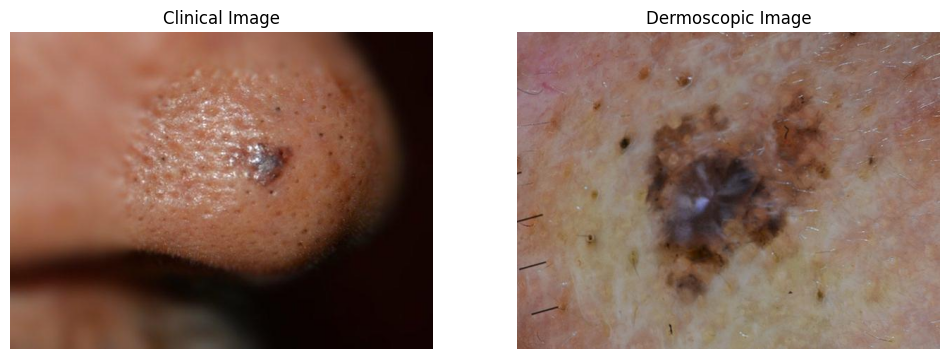

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

# Get image paths
clinical_path = clinical_files[0]
dermoscopic_path = dermoscopic_files[0]

# Load images
clinical_img = Image.open(clinical_path)
dermoscopic_img = Image.open(dermoscopic_path)

print("Clinical image size:", clinical_img.size)
print("Dermoscopic image size:", dermoscopic_img.size)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(clinical_img)
plt.title("Clinical Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dermoscopic_img)
plt.title("Dermoscopic Image")
plt.axis("off")

plt.show()

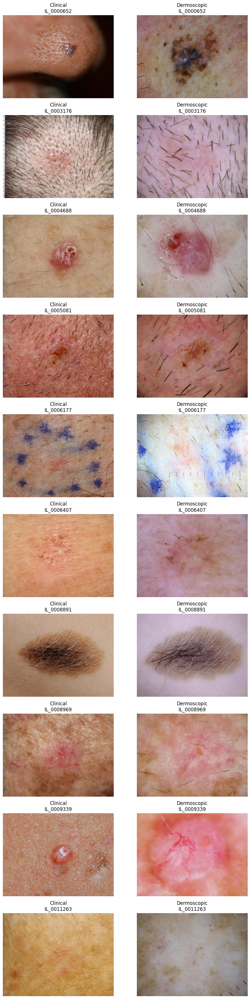

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
import glob

# Take first 10 lesions
sample = paired.head(10)

fig, axes = plt.subplots(10, 2, figsize=(10, 35))

for i, (_, row) in enumerate(sample.iterrows()):

    clinical_path = glob.glob(
        f"/kaggle/input/**/{row['isic_id_clinical']}.jpg",
        recursive=True
    )[0]

    dermoscopic_path = glob.glob(
        f"/kaggle/input/**/{row['isic_id_dermoscopic']}.jpg",
        recursive=True
    )[0]

    clinical_img = Image.open(clinical_path)
    dermoscopic_img = Image.open(dermoscopic_path)

    axes[i, 0].imshow(clinical_img)
    axes[i, 0].set_title(
        f"Clinical\n{row['lesion_id']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(dermoscopic_img)
    axes[i, 1].set_title(
        f"Dermoscopic\n{row['lesion_id']}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

# Image dimensions & format check

In [12]:
from PIL import Image
import glob
import os

# Check first 20 images
image_info = []

for _, row in paired.head(20).iterrows():

    clinical_path = glob.glob(
        f"/kaggle/input/**/{row['isic_id_clinical']}.jpg",
        recursive=True
    )[0]

    dermoscopic_path = glob.glob(
        f"/kaggle/input/**/{row['isic_id_dermoscopic']}.jpg",
        recursive=True
    )[0]

    clinical_img = Image.open(clinical_path)
    dermoscopic_img = Image.open(dermoscopic_path)

    image_info.append({
        "lesion_id": row["lesion_id"],
        "clinical_size": clinical_img.size,
        "clinical_mode": clinical_img.mode,
        "dermoscopic_size": dermoscopic_img.size,
        "dermoscopic_mode": dermoscopic_img.mode
    })

image_info_df = pd.DataFrame(image_info)

print(image_info_df)

     lesion_id clinical_size clinical_mode dermoscopic_size dermoscopic_mode
0   IL_0000652    (600, 450)           RGB       (600, 450)              RGB
1   IL_0003176    (600, 450)           RGB       (600, 450)              RGB
2   IL_0004688    (600, 450)           RGB       (600, 450)              RGB
3   IL_0005081    (600, 450)           RGB       (600, 450)              RGB
4   IL_0006177    (600, 450)           RGB       (600, 450)              RGB
5   IL_0006407    (600, 450)           RGB       (600, 450)              RGB
6   IL_0008891    (600, 450)           RGB       (600, 450)              RGB
7   IL_0008969    (600, 450)           RGB       (600, 450)              RGB
8   IL_0009339    (600, 450)           RGB       (600, 450)              RGB
9   IL_0011263    (600, 450)           RGB       (600, 450)              RGB
10  IL_0012199    (600, 450)           RGB       (600, 450)              RGB
11  IL_0014412    (600, 450)           RGB       (600, 450)              RGB

In [13]:
from collections import Counter
from PIL import Image
import os

base_path = "/kaggle/input/datasets/able23/skincancermilk10k/MILK10k_Training_Input"

clinical_sizes = Counter()
dermoscopic_sizes = Counter()

clinical_modes = Counter()
dermoscopic_modes = Counter()

for _, row in paired.iterrows():

    lesion_folder = os.path.join(
        base_path,
        row["lesion_id"]
    )

    clinical_path = os.path.join(
        lesion_folder,
        row["isic_id_clinical"] + ".jpg"
    )

    dermoscopic_path = os.path.join(
        lesion_folder,
        row["isic_id_dermoscopic"] + ".jpg"
    )

    with Image.open(clinical_path) as img:
        clinical_sizes[img.size] += 1
        clinical_modes[img.mode] += 1

    with Image.open(dermoscopic_path) as img:
        dermoscopic_sizes[img.size] += 1
        dermoscopic_modes[img.mode] += 1


print("Clinical image sizes:")
print(clinical_sizes)

print("\nDermoscopic image sizes:")
print(dermoscopic_sizes)

print("\nClinical image modes:")
print(clinical_modes)

print("\nDermoscopic image modes:")
print(dermoscopic_modes)

Clinical image sizes:
Counter({(600, 450): 5240})

Dermoscopic image sizes:
Counter({(600, 450): 5240})

Clinical image modes:
Counter({'RGB': 5240})

Dermoscopic image modes:
Counter({'RGB': 5240})


In [14]:
width = 600
height = 450

aspect_ratio = width / height

print("Width:", width)
print("Height:", height)
print("Aspect ratio:", aspect_ratio)
print("Aspect ratio (approximately): 4:3")

Width: 600
Height: 450
Aspect ratio: 1.3333333333333333
Aspect ratio (approximately): 4:3


# Demographic Metadata Exploration

In [15]:
import matplotlib.pyplot as plt

# Demographic columns
demo_cols = [
    "age_approx_clinical",
    "sex_clinical",
    "skin_tone_class_clinical",
    "site_clinical"
]

# Check distributions
for col in demo_cols:
    print("\n", "="*50)
    print(col)
    print(paired[col].value_counts(dropna=False))


age_approx_clinical
age_approx_clinical
70.0    753
65.0    734
75.0    607
60.0    595
55.0    483
50.0    429
80.0    370
85.0    339
45.0    276
40.0    227
35.0    132
30.0    107
25.0     53
20.0     38
15.0     27
10.0     26
5.0      24
NaN      20
Name: count, dtype: int64

sex_clinical
sex_clinical
male      3152
female    2088
Name: count, dtype: int64

skin_tone_class_clinical
skin_tone_class_clinical
3    3174
4    1066
2     506
5     383
1     105
0       6
Name: count, dtype: int64

site_clinical
site_clinical
trunk              1925
head_neck_face     1491
lower_extremity    1023
upper_extremity     667
hand                 72
NaN                  31
foot                 23
genital               8
Name: count, dtype: int64


# AGE

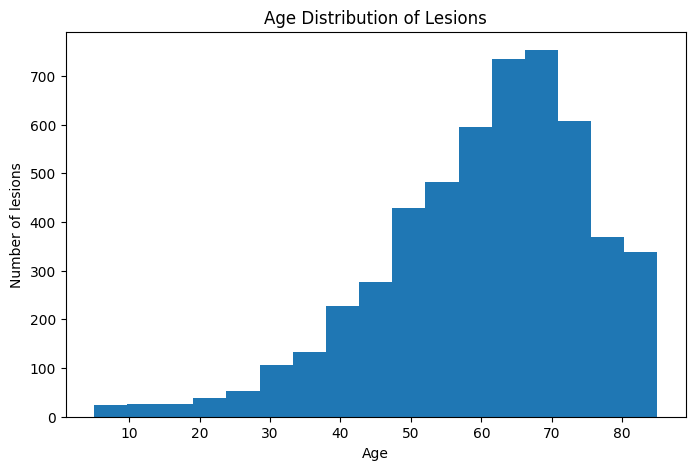

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

paired["age_approx_clinical"].dropna().plot(
    kind="hist",
    bins=17
)

plt.xlabel("Age")
plt.ylabel("Number of lesions")
plt.title("Age Distribution of Lesions")
plt.show()

# Distribution

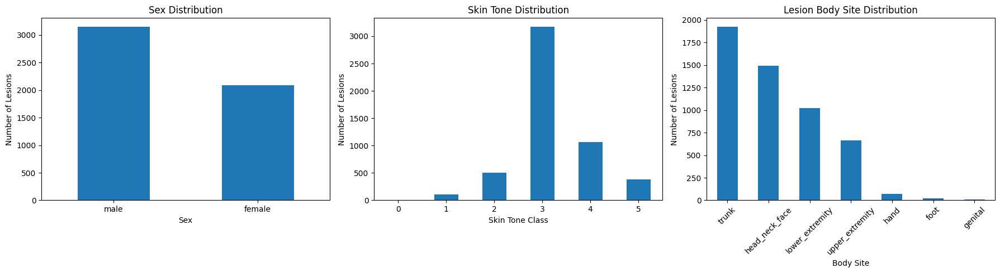

In [17]:
import matplotlib.pyplot as plt

# Create 3 plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Sex
paired["sex_clinical"].value_counts().plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Sex Distribution")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Number of Lesions")
axes[0].tick_params(axis="x", rotation=0)


# 2. Skin Tone
paired["skin_tone_class_clinical"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Skin Tone Distribution")
axes[1].set_xlabel("Skin Tone Class")
axes[1].set_ylabel("Number of Lesions")
axes[1].tick_params(axis="x", rotation=0)


# 3. Body Site
paired["site_clinical"].value_counts().plot(
    kind="bar",
    ax=axes[2]
)
axes[2].set_title("Lesion Body Site Distribution")
axes[2].set_xlabel("Body Site")
axes[2].set_ylabel("Number of Lesions")
axes[2].tick_params(axis="x", rotation=45)


plt.tight_layout()
plt.show()

In [18]:
# MONET feature columns
monet_cols = [
    "MONET_ulceration_crust_clinical",
    "MONET_hair_clinical",
    "MONET_vasculature_vessels_clinical",
    "MONET_erythema_clinical",
    "MONET_pigmented_clinical",
    "MONET_gel_water_drop_fluid_dermoscopy_liquid_clinical",
    "MONET_skin_markings_pen_ink_purple_pen_clinical"
]

# Display basic statistics
for col in monet_cols:
    
    print(col)
    print("Unique values:", paired[col].nunique())
    print("Min:", paired[col].min())
    print("Max:", paired[col].max())
    print("Mean:", paired[col].mean())
    print("Missing:", paired[col].isna().sum())

MONET_ulceration_crust_clinical
Unique values: 5238
Min: 0.0045189480567292
Max: 0.974614242750571
Mean: 0.3564109046310626
Missing: 0
MONET_hair_clinical
Unique values: 5238
Min: 0.0128604721215416
Max: 0.877227951179184
Mean: 0.1813754468432799
Missing: 0
MONET_vasculature_vessels_clinical
Unique values: 5238
Min: 3.89433313223264e-05
Max: 0.757917188601113
Mean: 0.01808352053107491
Missing: 0
MONET_erythema_clinical
Unique values: 5238
Min: 0.0068115717107399
Max: 0.901846792250988
Mean: 0.3595993370019922
Missing: 0
MONET_pigmented_clinical
Unique values: 5238
Min: 0.0041105165627812
Max: 0.97204730927872
Mean: 0.26841285370751045
Missing: 0
MONET_gel_water_drop_fluid_dermoscopy_liquid_clinical
Unique values: 5238
Min: 0.0051516038724096
Max: 0.831016437152892
Mean: 0.1620340525647701
Missing: 0
MONET_skin_markings_pen_ink_purple_pen_clinical
Unique values: 5238
Min: 0.0003450313651517
Max: 0.989992438135483
Mean: 0.18411129366804227
Missing: 0


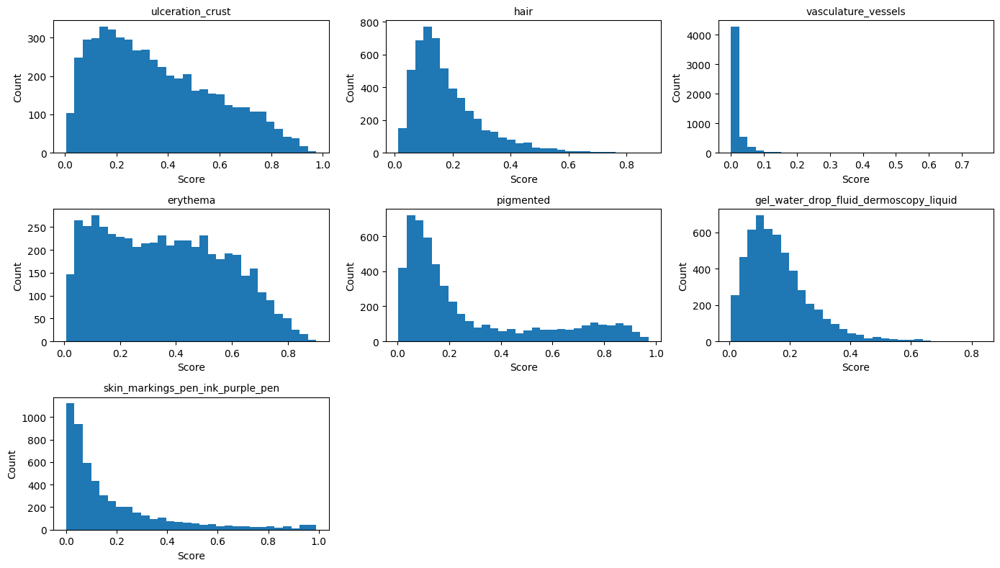

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

for i, col in enumerate(monet_cols, 1):
    plt.subplot(3, 3, i)
    
    plt.hist(
        paired[col],
        bins=30
    )
    
    # Shorter title for readability
    title = col.replace("MONET_", "").replace("_clinical", "")
    plt.title(title, fontsize=10)
    plt.xlabel("Score")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

               Ulceration  Hair  Vessels  Erythema  Pigmentation  Fluid  \
Ulceration           1.00 -0.30    -0.13      0.11         -0.21   0.05   
Hair                -0.30  1.00     0.17      0.01          0.15   0.10   
Vessels             -0.13  0.17     1.00      0.18         -0.21   0.22   
Erythema             0.11  0.01     0.18      1.00         -0.56   0.47   
Pigmentation        -0.21  0.15    -0.21     -0.56          1.00  -0.33   
Fluid                0.05  0.10     0.22      0.47         -0.33   1.00   
Skin_Markings       -0.26  0.28     0.03     -0.17          0.36  -0.02   

               Skin_Markings  
Ulceration             -0.26  
Hair                    0.28  
Vessels                 0.03  
Erythema               -0.17  
Pigmentation            0.36  
Fluid                  -0.02  
Skin_Markings           1.00  


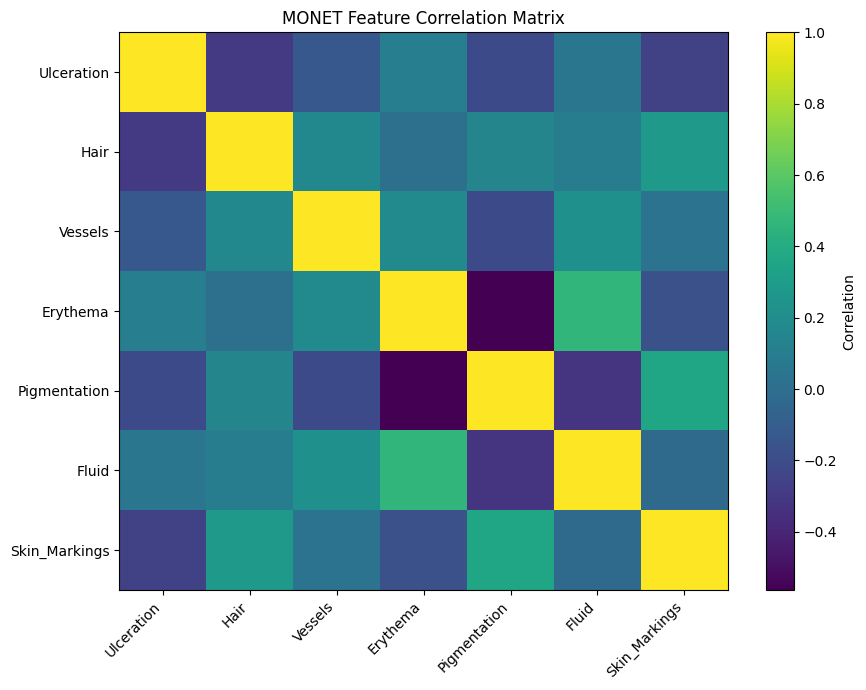

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# Select MONET features
monet_data = paired[monet_cols].copy()

# Short names for easier visualization
monet_data.columns = [
    "Ulceration",
    "Hair",
    "Vessels",
    "Erythema",
    "Pigmentation",
    "Fluid",
    "Skin_Markings"
]

# Calculate correlation
correlation = monet_data.corr()

# Display correlation matrix
print(correlation.round(2))

# Visualize correlation matrix
plt.figure(figsize=(9, 7))

plt.imshow(correlation, aspect="auto")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.colorbar(label="Correlation")

plt.title("MONET Feature Correlation Matrix")

plt.tight_layout()
plt.show()

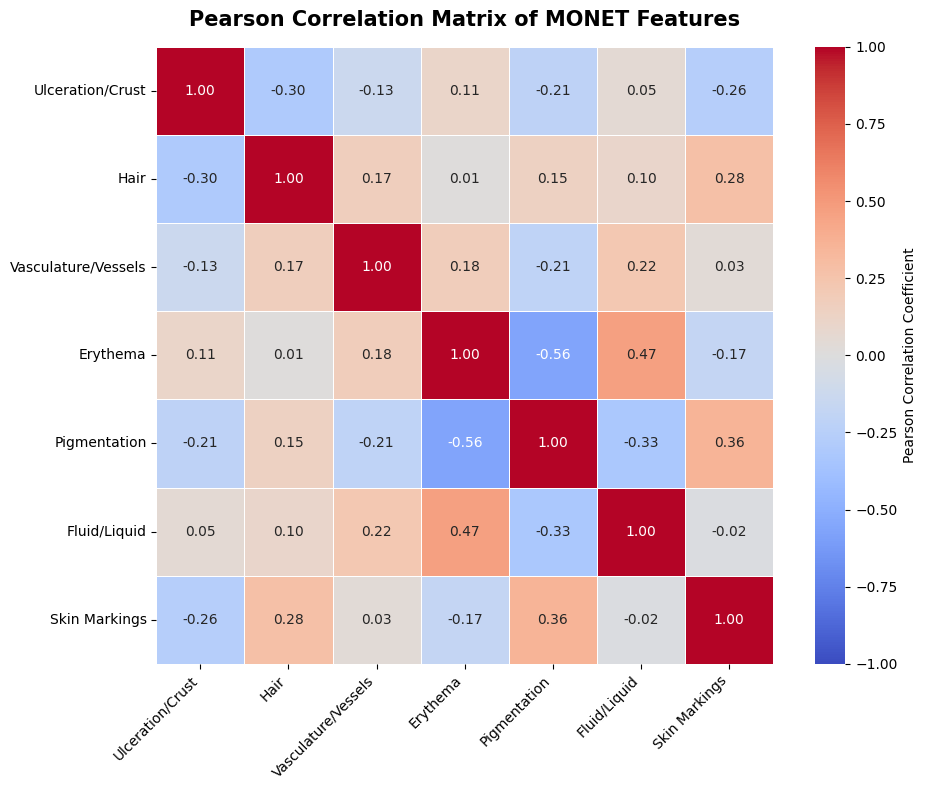

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select MONET features
monet_data = paired[monet_cols].copy()

# Short, publication-friendly feature names
monet_data.columns = [
    "Ulceration/Crust",
    "Hair",
    "Vasculature/Vessels",
    "Erythema",
    "Pigmentation",
    "Fluid/Liquid",
    "Skin Markings"
]

# Calculate Pearson correlation matrix
correlation = monet_data.corr(method="pearson")

# Plot
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Pearson Correlation Matrix of MONET Features",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [22]:
# Check image manipulation values
print("Unique values:")
print(paired["image_manipulation_clinical"].unique())

print("\nValue counts:")
print(
    paired["image_manipulation_clinical"]
    .value_counts(dropna=False)
)

# Percentage distribution
print("\nPercentage distribution:")
print(
    (paired["image_manipulation_clinical"]
     .value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Unique values:
['altered' 'instrument only']

Value counts:
image_manipulation_clinical
instrument only    4913
altered             327
Name: count, dtype: int64

Percentage distribution:
image_manipulation_clinical
instrument only    93.76
altered             6.24
Name: proportion, dtype: float64


In [23]:
groundtruth_path = (
    "/kaggle/input/datasets/able23/skincancermilk10k/"
    "MILK10k_Training_GroundTruth.csv"
)

groundtruth = pd.read_csv(groundtruth_path)

print("Shape:", groundtruth.shape)

print("\nColumns:")
print(groundtruth.columns.tolist())

print("\nFirst 5 rows:")
display(groundtruth.head())

Shape: (5240, 12)

Columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']

First 5 rows:


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0,1,0,0,0,0,0,0,0,0,0
1,IL_0003176,0,1,0,0,0,0,0,0,0,0,0
2,IL_0004688,0,1,0,0,0,0,0,0,0,0,0
3,IL_0005081,0,0,0,0,0,0,0,0,0,1,0
4,IL_0006177,0,1,0,0,0,0,0,0,0,0,0


In [24]:
target_cols = [
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

# Count how many positive labels each lesion has
label_counts = groundtruth[target_cols].sum(axis=1)

print("Number of lesions with exactly 1 label:",
      (label_counts == 1).sum())

print("Number of lesions with 0 labels:",
      (label_counts == 0).sum())

print("Number of lesions with more than 1 label:",
      (label_counts > 1).sum())

print("\nLabel-count distribution:")
print(label_counts.value_counts().sort_index())

Number of lesions with exactly 1 label: 5240
Number of lesions with 0 labels: 0
Number of lesions with more than 1 label: 0

Label-count distribution:
1    5240
Name: count, dtype: int64


In [25]:
# Convert one-hot encoded diagnosis into a single target column

groundtruth["diagnosis"] = groundtruth[target_cols].idxmax(axis=1)

print("Diagnosis column created successfully.\n")

print("First 10 diagnoses:")
display(
    groundtruth[["lesion_id", "diagnosis"]].head(10)
)

Diagnosis column created successfully.

First 10 diagnoses:


,lesion_id,diagnosis
0,IL_0000652,BCC
1,IL_0003176,BCC
2,IL_0004688,BCC
3,IL_0005081,SCCKA
4,IL_0006177,BCC
5,IL_0006407,AKIEC
6,IL_0008891,NV
7,IL_0008969,BCC
8,IL_0009339,BCC
9,IL_0011263,BCC


Diagnosis distribution:
diagnosis
BCC        2522
NV          746
BKL         544
SCCKA       473
MEL         450
AKIEC       303
DF           52
INF          50
VASC         47
BEN_OTH      44
MAL_OTH       9
Name: count, dtype: int64

Percentage distribution:
diagnosis
BCC        48.13
NV         14.24
BKL        10.38
SCCKA       9.03
MEL         8.59
AKIEC       5.78
DF          0.99
INF         0.95
VASC        0.90
BEN_OTH     0.84
MAL_OTH     0.17
Name: count, dtype: float64


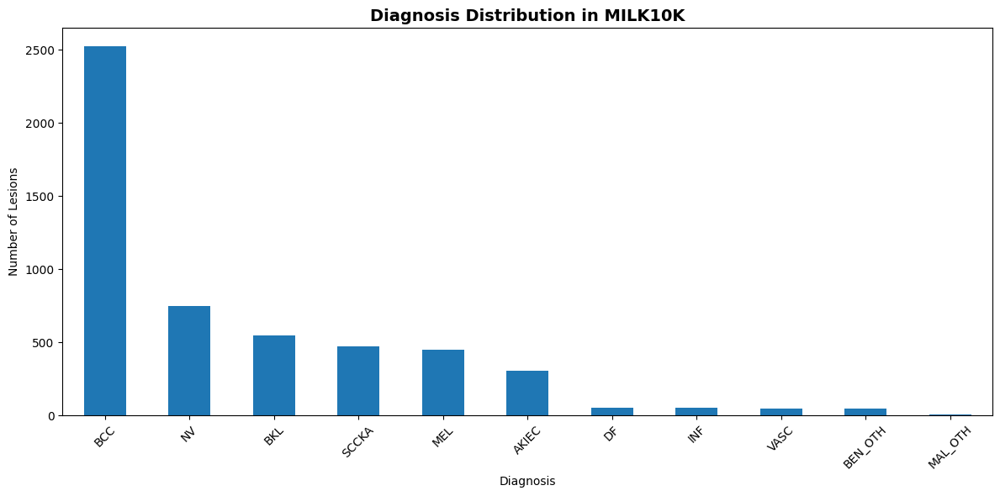

In [26]:
import matplotlib.pyplot as plt

diagnosis_counts = groundtruth["diagnosis"].value_counts()

print("Diagnosis distribution:")
print(diagnosis_counts)

print("\nPercentage distribution:")
print(
    (diagnosis_counts / len(groundtruth) * 100)
    .round(2)
)

plt.figure(figsize=(12, 6))

diagnosis_counts.sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Diagnosis Distribution in MILK10K", fontsize=14, fontweight="bold")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Lesions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Merge Diagnosis With the Paired Multimodal Data

In [27]:
# Merge ground-truth diagnosis with the paired clinical + dermoscopic data

paired = paired.merge(
    groundtruth[["lesion_id", "diagnosis"]],
    on="lesion_id",
    how="left"
)

print("Shape:", paired.shape)

print("\nDiagnosis missing values:")
print(paired["diagnosis"].isna().sum())

print("\nFirst 5 lesion IDs and diagnoses:")
display(
    paired[["lesion_id", "isic_id_clinical",
            "isic_id_dermoscopic", "diagnosis"]].head()
)

Shape: (5240, 34)

Diagnosis missing values:
0

First 5 lesion IDs and diagnoses:


,lesion_id,isic_id_clinical,isic_id_dermoscopic,diagnosis
0,IL_0000652,ISIC_8149219,ISIC_4671410,BCC
1,IL_0003176,ISIC_3904045,ISIC_5371928,BCC
2,IL_0004688,ISIC_0791494,ISIC_3624913,BCC
3,IL_0005081,ISIC_5667730,ISIC_5186409,SCCKA
4,IL_0006177,ISIC_8803389,ISIC_1048297,BCC


In [28]:
# Columns needed for our multimodal medical AI experiment

selected_cols = [
    "lesion_id",
    "isic_id_clinical",
    "isic_id_dermoscopic",
    "age_approx_clinical",
    "sex_clinical",
    "skin_tone_class_clinical",
    "site_clinical",
    "image_manipulation_clinical",
    "diagnosis"
] + monet_cols

model_data = paired[selected_cols].copy()

print("Shape:", model_data.shape)

print("\nColumns:")
print(model_data.columns.tolist())

print("\nMissing values:")
print(model_data.isna().sum())

Shape: (5240, 16)

Columns:
['lesion_id', 'isic_id_clinical', 'isic_id_dermoscopic', 'age_approx_clinical', 'sex_clinical', 'skin_tone_class_clinical', 'site_clinical', 'image_manipulation_clinical', 'diagnosis', 'MONET_ulceration_crust_clinical', 'MONET_hair_clinical', 'MONET_vasculature_vessels_clinical', 'MONET_erythema_clinical', 'MONET_pigmented_clinical', 'MONET_gel_water_drop_fluid_dermoscopy_liquid_clinical', 'MONET_skin_markings_pen_ink_purple_pen_clinical']

Missing values:
lesion_id                                                 0
isic_id_clinical                                          0
isic_id_dermoscopic                                       0
age_approx_clinical                                      20
sex_clinical                                              0
skin_tone_class_clinical                                  0
site_clinical                                            31
image_manipulation_clinical                               0
diagnosis                      

In [29]:
print("Total rows:", len(model_data))

print("\nDuplicate lesion IDs:")
print(model_data["lesion_id"].duplicated().sum())

print("\nDuplicate clinical image IDs:")
print(model_data["isic_id_clinical"].duplicated().sum())

print("\nDuplicate dermoscopic image IDs:")
print(model_data["isic_id_dermoscopic"].duplicated().sum())

print("\nDuplicate complete rows:")
print(model_data.duplicated().sum())

Total rows: 5240

Duplicate lesion IDs:
0

Duplicate clinical image IDs:
0

Duplicate dermoscopic image IDs:
0

Duplicate complete rows:
0


In [30]:
# Verify that every lesion has exactly one image of each type

clinical_per_lesion = (
    model_data.groupby("lesion_id")["isic_id_clinical"]
    .nunique()
)

dermoscopic_per_lesion = (
    model_data.groupby("lesion_id")["isic_id_dermoscopic"]
    .nunique()
)

print("Lesions with exactly 1 clinical image:",
      (clinical_per_lesion == 1).sum())

print("Lesions with exactly 1 dermoscopic image:",
      (dermoscopic_per_lesion == 1).sum())

print("\nLesions with unexpected clinical image count:",
      (clinical_per_lesion != 1).sum())

print("Lesions with unexpected dermoscopic image count:",
      (dermoscopic_per_lesion != 1).sum())

Lesions with exactly 1 clinical image: 5240
Lesions with exactly 1 dermoscopic image: 5240

Lesions with unexpected clinical image count: 0
Lesions with unexpected dermoscopic image count: 0


In [31]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_data, temp_data = train_test_split(
    model_data,
    test_size=0.30,
    stratify=model_data["diagnosis"],
    random_state=42
)

# Second split: divide the temporary 30% into
# 15% validation and 15% test
val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["diagnosis"],
    random_state=42
)

print("Train size:", len(train_data))
print("Validation size:", len(val_data))
print("Test size:", len(test_data))

print("\nTotal:", len(train_data) + len(val_data) + len(test_data))

Train size: 3668
Validation size: 786
Test size: 786

Total: 5240


In [32]:
train_ids = set(train_data["lesion_id"])
val_ids = set(val_data["lesion_id"])
test_ids = set(test_data["lesion_id"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

print("\nUnique lesions across all splits:",
      len(train_ids | val_ids | test_ids))

print("Total lesions:", len(model_data))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Unique lesions across all splits: 5240
Total lesions: 5240


In [33]:
# Compare diagnosis distribution across train, validation, and test

split_distribution = pd.DataFrame({
    "Train": train_data["diagnosis"].value_counts(normalize=True) * 100,
    "Validation": val_data["diagnosis"].value_counts(normalize=True) * 100,
    "Test": test_data["diagnosis"].value_counts(normalize=True) * 100
}).round(2)

print("Diagnosis distribution (%) across splits:")
display(split_distribution)

Diagnosis distribution (%) across splits:


,Train,Validation,Test
diagnosis,,,
AKIEC,5.78,5.85,5.73
BCC,48.12,48.22,48.09
BEN_OTH,0.85,0.76,0.89
BKL,10.39,10.43,10.31
DF,1.01,0.89,1.02
INF,0.95,0.89,1.02
MAL_OTH,0.16,0.25,0.13
MEL,8.59,8.52,8.65
NV,14.23,14.25,14.25


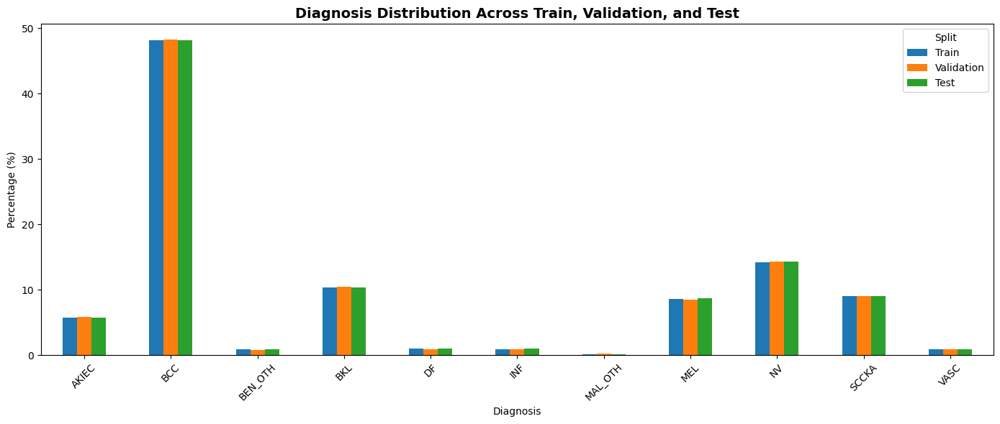

In [34]:
split_distribution.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title(
    "Diagnosis Distribution Across Train, Validation, and Test",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Diagnosis")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Split")

plt.tight_layout()
plt.show()

In [35]:
# Handle missing categorical metadata

for df in [train_data, val_data, test_data]:
    df["site_clinical"] = df["site_clinical"].fillna("Unknown")

print("Missing site values:")
print("Train:", train_data["site_clinical"].isna().sum())
print("Validation:", val_data["site_clinical"].isna().sum())
print("Test:", test_data["site_clinical"].isna().sum())

print("\nSite categories:")
print(sorted(model_data["site_clinical"].dropna().unique().tolist() + ["Unknown"]))

Missing site values:
Train: 0
Validation: 0
Test: 0

Site categories:
['Unknown', 'foot', 'genital', 'hand', 'head_neck_face', 'lower_extremity', 'trunk', 'upper_extremity']


In [36]:
# Calculate median age using TRAINING data only

train_age_median = train_data["age_approx_clinical"].median()

print("Training-set median age:", train_age_median)

# Fill missing age using the training median
for df in [train_data, val_data, test_data]:
    df["age_approx_clinical"] = df["age_approx_clinical"].fillna(
        train_age_median
    )

print("\nMissing age values after imputation:")
print("Train:", train_data["age_approx_clinical"].isna().sum())
print("Validation:", val_data["age_approx_clinical"].isna().sum())
print("Test:", test_data["age_approx_clinical"].isna().sum())

Training-set median age: 65.0

Missing age values after imputation:
Train: 0
Validation: 0
Test: 0


In [38]:
# Final check after metadata preprocessing

print("=" * 60)
print("FINAL SPLIT & METADATA CHECK")
print("=" * 60)

# 1. Dataset sizes
print("\n1. Split sizes:")
print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

# 2. Missing values
print("\n2. Missing values:")

for name, df in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    print(f"\n{name}:")
    print(df.isna().sum()[df.isna().sum() > 0])

# 3. Lesion overlap check
train_ids = set(train_data["lesion_id"])
val_ids = set(val_data["lesion_id"])
test_ids = set(test_data["lesion_id"])

print("\n3. Lesion leakage check:")
print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

# 4. Total unique lesions
all_ids = train_ids | val_ids | test_ids

print("\n4. Unique lesions:")
print("Across splits:", len(all_ids))
print("Original:", model_data["lesion_id"].nunique())

# 5. Target check
print("\n5. Diagnosis classes:")
print("Train:", train_data["diagnosis"].nunique())
print("Validation:", val_data["diagnosis"].nunique())
print("Test:", test_data["diagnosis"].nunique())

print("\nDiagnosis classes:")
print(sorted(model_data["diagnosis"].unique()))

print("\n" + "=" * 60)
print("CHECK COMPLETE")
print("=" * 60)

FINAL SPLIT & METADATA CHECK

1. Split sizes:
Train: (3668, 16)
Validation: (786, 16)
Test: (786, 16)

2. Missing values:

Train:
Series([], dtype: int64)

Validation:
Series([], dtype: int64)

Test:
Series([], dtype: int64)

3. Lesion leakage check:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

4. Unique lesions:
Across splits: 5240
Original: 5240

5. Diagnosis classes:
Train: 11
Validation: 11
Test: 11

Diagnosis classes:
['AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']

CHECK COMPLETE


In [39]:


import os

IMAGE_ROOT = "/kaggle/input/milk10k/MILK10k_Training_Input"

def find_image(lesion_id, image_type):
    folder = os.path.join(IMAGE_ROOT, lesion_id)
    
    if not os.path.exists(folder):
        return None
    
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            # Use metadata image_type to identify the modality
            if image_type.lower() in filename.lower():
                return os.path.join(folder, filename)
    
    return None


# Check the actual columns first
print("Columns:")
print(train_data.columns.tolist())

Columns:
['lesion_id', 'isic_id_clinical', 'isic_id_dermoscopic', 'age_approx_clinical', 'sex_clinical', 'skin_tone_class_clinical', 'site_clinical', 'image_manipulation_clinical', 'diagnosis', 'MONET_ulceration_crust_clinical', 'MONET_hair_clinical', 'MONET_vasculature_vessels_clinical', 'MONET_erythema_clinical', 'MONET_pigmented_clinical', 'MONET_gel_water_drop_fluid_dermoscopy_liquid_clinical', 'MONET_skin_markings_pen_ink_purple_pen_clinical']


In [40]:
#  Create clinical and dermoscopic image paths

import os

IMAGE_ROOT = "/kaggle/input/milk10k/MILK10k_Training_Input"

def get_image_path(lesion_id, isic_id):
    """
    Find the image file belonging to a lesion and ISIC ID.
    """
    lesion_folder = os.path.join(IMAGE_ROOT, lesion_id)

    if not os.path.isdir(lesion_folder):
        return None

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        path = os.path.join(lesion_folder, isic_id + ext)
        if os.path.exists(path):
            return path

    return None


# Create paths for each split
for df in [train_data, val_data, test_data]:
    df["clinical_path"] = df.apply(
        lambda row: get_image_path(
            row["lesion_id"],
            row["isic_id_clinical"]
        ),
        axis=1
    )

    df["dermoscopic_path"] = df.apply(
        lambda row: get_image_path(
            row["lesion_id"],
            row["isic_id_dermoscopic"]
        ),
        axis=1
    )


print("Clinical paths found:")
print("Train:", train_data["clinical_path"].notna().sum(), "/", len(train_data))
print("Validation:", val_data["clinical_path"].notna().sum(), "/", len(val_data))
print("Test:", test_data["clinical_path"].notna().sum(), "/", len(test_data))

print("\nDermoscopic paths found:")
print("Train:", train_data["dermoscopic_path"].notna().sum(), "/", len(train_data))
print("Validation:", val_data["dermoscopic_path"].notna().sum(), "/", len(val_data))
print("Test:", test_data["dermoscopic_path"].notna().sum(), "/", len(test_data))

Clinical paths found:
Train: 0 / 3668
Validation: 0 / 786
Test: 0 / 786

Dermoscopic paths found:
Train: 0 / 3668
Validation: 0 / 786
Test: 0 / 786


In [41]:
#  Create image paths

from pathlib import Path

BASE_PATH = "/kaggle/input/datasets/able23/skincancermilk10k"
IMAGE_BASE = Path(BASE_PATH) / "MILK10k_Training_Input"


def get_image_path(lesion_id, isic_id):
    """Return the image path for a lesion and ISIC ID."""
    
    path = IMAGE_BASE / str(lesion_id) / f"{isic_id}.jpg"
    
    if path.exists():
        return str(path)
    
    return None


# Create paths
for df in [train_data, val_data, test_data]:
    
    df["clinical_path"] = df.apply(
        lambda row: get_image_path(
            row["lesion_id"],
            row["isic_id_clinical"]
        ),
        axis=1
    )
    
    df["dermoscopic_path"] = df.apply(
        lambda row: get_image_path(
            row["lesion_id"],
            row["isic_id_dermoscopic"]
        ),
        axis=1
    )


# Check results
print("Clinical paths found:")
print("Train:", train_data["clinical_path"].notna().sum(), "/", len(train_data))
print("Validation:", val_data["clinical_path"].notna().sum(), "/", len(val_data))
print("Test:", test_data["clinical_path"].notna().sum(), "/", len(test_data))

print("\nDermoscopic paths found:")
print("Train:", train_data["dermoscopic_path"].notna().sum(), "/", len(train_data))
print("Validation:", val_data["dermoscopic_path"].notna().sum(), "/", len(val_data))
print("Test:", test_data["dermoscopic_path"].notna().sum(), "/", len(test_data))

Clinical paths found:
Train: 3668 / 3668
Validation: 786 / 786
Test: 786 / 786

Dermoscopic paths found:
Train: 3668 / 3668
Validation: 786 / 786
Test: 786 / 786


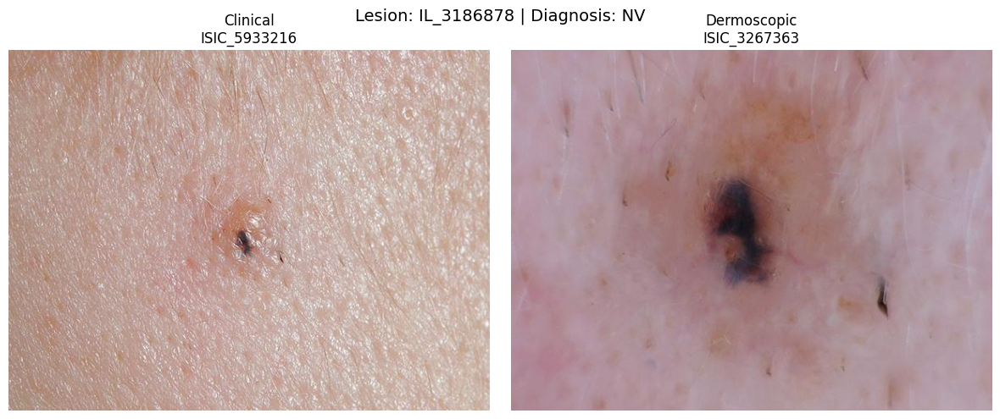

Lesion ID: IL_3186878
Diagnosis: NV
Clinical size: (600, 450)
Clinical mode: RGB
Dermoscopic size: (600, 450)
Dermoscopic mode: RGB


In [42]:
# Visual verification of one clinical + dermoscopic pair

from PIL import Image
import matplotlib.pyplot as plt

# Select the first training sample
sample = train_data.iloc[0]

# Load both images
clinical_img = Image.open(sample["clinical_path"]).convert("RGB")
dermoscopic_img = Image.open(sample["dermoscopic_path"]).convert("RGB")

# Display side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(clinical_img)
axes[0].set_title(f"Clinical\n{sample['isic_id_clinical']}")
axes[0].axis("off")

axes[1].imshow(dermoscopic_img)
axes[1].set_title(f"Dermoscopic\n{sample['isic_id_dermoscopic']}")
axes[1].axis("off")

plt.suptitle(
    f"Lesion: {sample['lesion_id']} | Diagnosis: {sample['diagnosis']}",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Basic image information
print("Lesion ID:", sample["lesion_id"])
print("Diagnosis:", sample["diagnosis"])
print("Clinical size:", clinical_img.size)
print("Clinical mode:", clinical_img.mode)
print("Dermoscopic size:", dermoscopic_img.size)
print("Dermoscopic mode:", dermoscopic_img.mode)

In [43]:
# Define image preprocessing

from torchvision import transforms

IMAGE_SIZE = 224

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

# Validation and test transformations
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

print("Image preprocessing defined successfully.")
print("Target image size:", IMAGE_SIZE, "x", IMAGE_SIZE)

Image preprocessing defined successfully.
Target image size: 224 x 224


In [44]:
#  Image preprocessing pipeline

import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_SIZE = 224

# Resize while preserving aspect ratio, then pad to 224x224
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.Pad((0, 28, 0, 28)),  # 224x168 -> 224x224
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing:")
print("Original size: 600 x 450")
print("Target size: 224 x 224")
print("Aspect ratio preserved: Yes")
print("Normalization: ImageNet")

Image preprocessing:
Original size: 600 x 450
Target size: 224 x 224
Aspect ratio preserved: Yes
Normalization: ImageNet


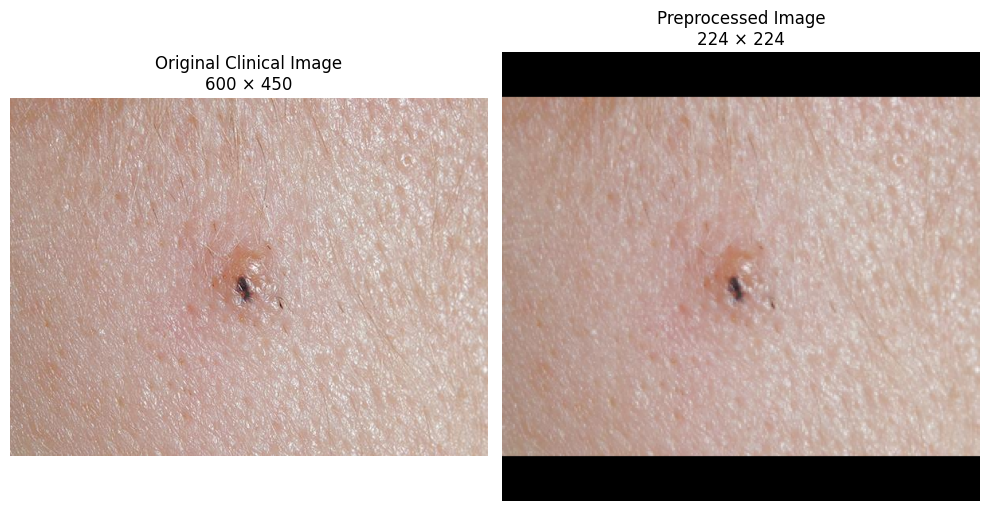

Original size: (600, 450)
Processed tensor: torch.Size([3, 280, 298])


In [46]:
# Cell 47: Visualize the preprocessed image

import numpy as np

sample = train_data.iloc[0]

# Load original image
original = Image.open(sample["clinical_path"]).convert("RGB")

# Apply preprocessing
processed_tensor = image_transform(original)

# Undo ImageNet normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

visual_tensor = processed_tensor * std + mean
visual_tensor = torch.clamp(visual_tensor, 0, 1)

# Convert tensor to image
processed_image = visual_tensor.permute(1, 2, 0).numpy()

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original)
axes[0].set_title("Original Clinical Image\n600 × 450")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title("Preprocessed Image\n224 × 224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original size:", original.size)
print("Processed tensor:", processed_tensor.shape)

In [48]:
# Aspect-ratio preserving preprocessing

import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_SIZE = 224

# Original image: 600 x 450 = 4:3
# Resize to 224 x 168, then pad vertically to 224 x 224
image_transform = transforms.Compose([
    transforms.Resize((168, 224)),
    transforms.Pad((0, 28, 0, 28)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing:")
print("Original size: 600 x 450")
print("Resized size: 224 x 168")
print("Final size: 224 x 224")
print("Aspect ratio preserved: Yes")
print("Normalization: ImageNet")

Image preprocessing:
Original size: 600 x 450
Resized size: 224 x 168
Final size: 224 x 224
Aspect ratio preserved: Yes
Normalization: ImageNet


In [49]:
# Verify corrected preprocessing

sample = train_data.iloc[0]

original = Image.open(sample["clinical_path"]).convert("RGB")

processed_tensor = image_transform(original)

print("Original size:", original.size)
print("Processed tensor shape:", processed_tensor.shape)
print("Tensor dtype:", processed_tensor.dtype)

Original size: (600, 450)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32


In [50]:
#  Prepare target labels and metadata

import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---------------------------------------------------------
# 1. Diagnosis label encoding
# ---------------------------------------------------------

# Create label mapping from the complete set of known classes
classes = sorted(model_data["diagnosis"].dropna().unique())

label_to_idx = {label: idx for idx, label in enumerate(classes)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}

# Apply mapping
for df in [train_data, val_data, test_data]:
    df["label"] = df["diagnosis"].map(label_to_idx).astype(int)


print("Diagnosis classes:")
print(label_to_idx)


# ---------------------------------------------------------
# 2. Metadata columns
# ---------------------------------------------------------

numeric_cols = [
    "age_approx_clinical",
    "MONET_ulceration_crust_clinical",
    "MONET_hair_clinical",
    "MONET_vasculature_vessels_clinical",
    "MONET_erythema_clinical",
    "MONET_pigmented_clinical",
    "MONET_gel_water_drop_fluid_dermoscopy_liquid_clinical",
    "MONET_skin_markings_pen_ink_purple_pen_clinical"
]

categorical_cols = [
    "sex_clinical",
    "skin_tone_class_clinical",
    "site_clinical"
]


# ---------------------------------------------------------
# 3. Numeric preprocessing
#    FIT ONLY on training data
# ---------------------------------------------------------

scaler = StandardScaler()

train_numeric = scaler.fit_transform(
    train_data[numeric_cols].astype(float)
)

val_numeric = scaler.transform(
    val_data[numeric_cols].astype(float)
)

test_numeric = scaler.transform(
    test_data[numeric_cols].astype(float)
)


# ---------------------------------------------------------
# 4. Categorical preprocessing
#    FIT ONLY on training data
# ---------------------------------------------------------

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

train_categorical = encoder.fit_transform(
    train_data[categorical_cols].astype(str)
)

val_categorical = encoder.transform(
    val_data[categorical_cols].astype(str)
)

test_categorical = encoder.transform(
    test_data[categorical_cols].astype(str)
)


# ---------------------------------------------------------
# 5. Combine numeric + categorical metadata
# ---------------------------------------------------------

train_metadata = np.hstack([
    train_numeric,
    train_categorical
]).astype(np.float32)

val_metadata = np.hstack([
    val_numeric,
    val_categorical
]).astype(np.float32)

test_metadata = np.hstack([
    test_numeric,
    test_categorical
]).astype(np.float32)


# ---------------------------------------------------------
# 6. Final checks
# ---------------------------------------------------------

print("\nMetadata shapes:")
print("Train:", train_metadata.shape)
print("Validation:", val_metadata.shape)
print("Test:", test_metadata.shape)

print("\nLabel shapes:")
print("Train:", train_data["label"].shape)
print("Validation:", val_data["label"].shape)
print("Test:", test_data["label"].shape)

print("\nNumber of classes:", len(classes))
print("Metadata features:", train_metadata.shape[1])

Diagnosis classes:
{'AKIEC': 0, 'BCC': 1, 'BEN_OTH': 2, 'BKL': 3, 'DF': 4, 'INF': 5, 'MAL_OTH': 6, 'MEL': 7, 'NV': 8, 'SCCKA': 9, 'VASC': 10}

Metadata shapes:
Train: (3668, 24)
Validation: (786, 24)
Test: (786, 24)

Label shapes:
Train: (3668,)
Validation: (786,)
Test: (786,)

Number of classes: 11
Metadata features: 24


In [51]:
#  Multimodal PyTorch Dataset

import torch
from torch.utils.data import Dataset

class MILK10KDataset(Dataset):
    
    def __init__(self, dataframe, metadata, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.metadata = torch.tensor(metadata, dtype=torch.float32)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        
        row = self.dataframe.iloc[idx]

        # Load clinical image
        clinical_image = Image.open(
            row["clinical_path"]
        ).convert("RGB")

        # Load dermoscopic image
        dermoscopic_image = Image.open(
            row["dermoscopic_path"]
        ).convert("RGB")

        # Apply image preprocessing
        if self.transform is not None:
            clinical_image = self.transform(clinical_image)
            dermoscopic_image = self.transform(dermoscopic_image)

        # Metadata
        metadata = self.metadata[idx]

        # Diagnosis label
        label = torch.tensor(
            row["label"],
            dtype=torch.long
        )

        return {
            "clinical": clinical_image,
            "dermoscopic": dermoscopic_image,
            "metadata": metadata,
            "label": label,
            "lesion_id": row["lesion_id"]
        }


# Create datasets
train_dataset = MILK10KDataset(
    train_data,
    train_metadata,
    transform=image_transform
)

val_dataset = MILK10KDataset(
    val_data,
    val_metadata,
    transform=image_transform
)

test_dataset = MILK10KDataset(
    test_data,
    test_metadata,
    transform=image_transform
)


print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Dataset sizes:
Train: 3668
Validation: 786
Test: 786


In [52]:
# Test one multimodal sample

sample = train_dataset[0]

print("Clinical image:", sample["clinical"].shape)
print("Dermoscopic image:", sample["dermoscopic"].shape)
print("Metadata:", sample["metadata"].shape)
print("Label:", sample["label"].item())
print("Lesion ID:", sample["lesion_id"])

Clinical image: torch.Size([3, 224, 224])
Dermoscopic image: torch.Size([3, 224, 224])
Metadata: torch.Size([24])
Label: 8
Lesion ID: IL_3186878


In [53]:
# Create PyTorch DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
Train batches: 115
Validation batches: 25
Test batches: 25


In [56]:
#  Clinical CNN Baseline

import torch
import torch.nn as nn
from torchvision import models

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

NUM_CLASSES = 11


class ClinicalCNN(nn.Module):
    
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # ResNet18 WITHOUT downloading pretrained weights
        self.backbone = models.resnet18(weights=None)

        # Replace classifier
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(
            in_features,
            num_classes
        )

    def forward(self, x):
        return self.backbone(x)


# Create model
clinical_model = ClinicalCNN().to(device)

print("\nClinical model created successfully.")
print("Number of classes:", NUM_CLASSES)
print("Model device:", next(clinical_model.parameters()).device)

Device: cpu

Clinical model created successfully.
Number of classes: 11
Model device: cpu


In [57]:
# Cell 53: Clinical CNN forward-pass test

batch = next(iter(train_loader))

clinical_images = batch["clinical"].to(device)
labels = batch["label"].to(device)

clinical_model.eval()

with torch.no_grad():
    outputs = clinical_model(clinical_images)

print("Input shape:", clinical_images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 11])
Labels shape: torch.Size([32])


In [58]:
import torch.nn as nn

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    clinical_model.parameters(),
    lr=1e-4
)

# Number of epochs for initial baseline
NUM_EPOCHS = 1

print("Training setup completed.")
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 1e-4)
print("Epochs:", NUM_EPOCHS)

Training setup completed.
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Epochs: 1


In [59]:
import torch

clinical_model.train()

running_loss = 0.0
correct = 0
total = 0

for batch_idx, batch in enumerate(train_loader):

    # Get clinical images and labels
    images = batch["clinical"].to(device)
    labels = batch["label"].to(device)

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = clinical_model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backward pass
    loss.backward()

    # Update model weights
    optimizer.step()

    # Statistics
    running_loss += loss.item()

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    # Progress
    if (batch_idx + 1) % 20 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

# Epoch statistics
train_loss = running_loss / len(train_loader)
train_accuracy = 100 * correct / total

print("\n===== Clinical CNN Training Result =====")
print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.2f}%")

Batch [20/115] Loss: 1.4760
Batch [40/115] Loss: 1.2866
Batch [60/115] Loss: 1.4480
Batch [80/115] Loss: 1.4263
Batch [100/115] Loss: 1.7576

===== Clinical CNN Training Result =====
Training Loss: 1.5299
Training Accuracy: 50.30%


In [60]:
clinical_model.eval()

val_loss = 0.0
val_correct = 0
val_total = 0

with torch.no_grad():
    for batch in val_loader:

        # Clinical images and labels
        images = batch["clinical"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = clinical_model(images)

        # Validation loss
        loss = criterion(outputs, labels)

        val_loss += loss.item()

        # Predictions
        predictions = outputs.argmax(dim=1)

        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

# Calculate validation metrics
val_loss = val_loss / len(val_loader)
val_accuracy = 100 * val_correct / val_total

print("===== Clinical CNN Validation Result =====")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")

===== Clinical CNN Validation Result =====
Validation Loss: 1.3176
Validation Accuracy: 57.12%


In [61]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

clinical_model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for batch in val_loader:
        images = batch["clinical"].to(device)
        labels = batch["label"].to(device)

        outputs = clinical_model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# Multiclass AUC
y_true_binary = label_binarize(
    all_labels,
    classes=np.arange(NUM_CLASSES)
)

auc = roc_auc_score(
    y_true_binary,
    all_probabilities,
    multi_class="ovr",
    average="macro"
)

print("===== Clinical CNN Validation Metrics =====")
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")

===== Clinical CNN Validation Metrics =====
Accuracy : 0.5712 (57.12%)
Precision: 0.2211
Recall   : 0.1679
F1-score : 0.1468
AUC      : 0.8043


<Figure size 1000x1000 with 0 Axes>

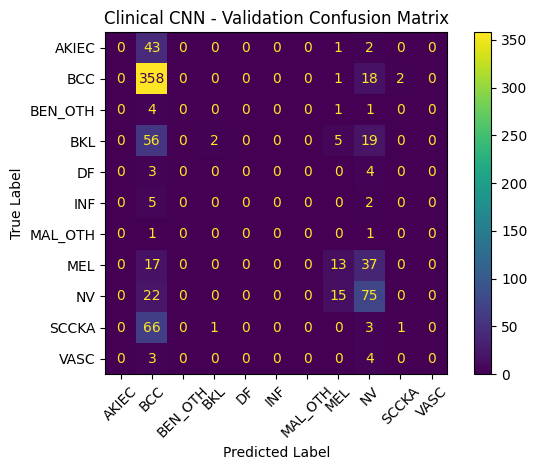

In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES)
)

# Class names in the same order as label encoding
class_names = [
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

plt.figure(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title("Clinical CNN - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [63]:
import torch
import torch.nn as nn
from torchvision import models

# Use the same device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 11

class DermoscopicCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # No pretrained weights to avoid downloading
        self.backbone = models.resnet18(weights=None)

        # Replace final classification layer
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.backbone(x)


# Create model
dermoscopic_model = DermoscopicCNN().to(device)

print("Dermoscopic CNN created successfully.")
print("Number of classes:", NUM_CLASSES)
print("Model device:", next(dermoscopic_model.parameters()).device)

Dermoscopic CNN created successfully.
Number of classes: 11
Model device: cpu


In [64]:
# Get one batch
batch = next(iter(train_loader))

# Use dermoscopic images
dermoscopic_images = batch["dermoscopic"].to(device)
labels = batch["label"].to(device)

dermoscopic_model.eval()

with torch.no_grad():
    outputs = dermoscopic_model(dermoscopic_images)

print("Input shape:", dermoscopic_images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 11])
Labels shape: torch.Size([32])


In [65]:
# Loss function and optimizer for Dermoscopic CNN
dermoscopic_criterion = nn.CrossEntropyLoss()

dermoscopic_optimizer = torch.optim.Adam(
    dermoscopic_model.parameters(),
    lr=1e-4
)

NUM_EPOCHS = 1

print("Dermoscopic training setup completed.")
print("Loss function:", dermoscopic_criterion)
print("Optimizer:", dermoscopic_optimizer.__class__.__name__)
print("Learning rate:", 1e-4)
print("Epochs:", NUM_EPOCHS)

Dermoscopic training setup completed.
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Epochs: 1


In [66]:
dermoscopic_model.train()

running_loss = 0.0
correct = 0
total = 0

for batch_idx, batch in enumerate(train_loader):

    # Get dermoscopic images and labels
    images = batch["dermoscopic"].to(device)
    labels = batch["label"].to(device)

    # Clear gradients
    dermoscopic_optimizer.zero_grad()

    # Forward pass
    outputs = dermoscopic_model(images)

    # Calculate loss
    loss = dermoscopic_criterion(outputs, labels)

    # Backward pass
    loss.backward()

    # Update weights
    dermoscopic_optimizer.step()

    # Statistics
    running_loss += loss.item()

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    # Progress
    if (batch_idx + 1) % 20 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

# Epoch statistics
dermoscopic_train_loss = running_loss / len(train_loader)
dermoscopic_train_accuracy = 100 * correct / total

print("\n===== Dermoscopic CNN Training Result =====")
print(f"Training Loss: {dermoscopic_train_loss:.4f}")
print(f"Training Accuracy: {dermoscopic_train_accuracy:.2f}%")

Batch [20/115] Loss: 1.3008
Batch [40/115] Loss: 1.3889
Batch [60/115] Loss: 1.3049
Batch [80/115] Loss: 1.2762
Batch [100/115] Loss: 1.5596

===== Dermoscopic CNN Training Result =====
Training Loss: 1.3948
Training Accuracy: 55.18%


In [67]:
dermoscopic_model.eval()

dermoscopic_val_loss = 0.0
dermoscopic_val_correct = 0
dermoscopic_val_total = 0

with torch.no_grad():
    for batch in val_loader:

        # Dermoscopic images and labels
        images = batch["dermoscopic"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = dermoscopic_model(images)

        # Validation loss
        loss = dermoscopic_criterion(outputs, labels)

        dermoscopic_val_loss += loss.item()

        # Predictions
        predictions = outputs.argmax(dim=1)

        dermoscopic_val_correct += (
            predictions == labels
        ).sum().item()

        dermoscopic_val_total += labels.size(0)

# Calculate validation metrics
dermoscopic_val_loss = (
    dermoscopic_val_loss / len(val_loader)
)

dermoscopic_val_accuracy = (
    100 * dermoscopic_val_correct / dermoscopic_val_total
)

print("===== Dermoscopic CNN Validation Result =====")
print(f"Validation Loss: {dermoscopic_val_loss:.4f}")
print(
    f"Validation Accuracy: "
    f"{dermoscopic_val_accuracy:.2f}%"
)

===== Dermoscopic CNN Validation Result =====
Validation Loss: 1.3142
Validation Accuracy: 56.62%


In [68]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

dermoscopic_model.eval()

all_derm_labels = []
all_derm_predictions = []
all_derm_probabilities = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["dermoscopic"].to(device)
        labels = batch["label"].to(device)

        outputs = dermoscopic_model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        all_derm_labels.extend(labels.cpu().numpy())
        all_derm_predictions.extend(predictions.cpu().numpy())
        all_derm_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy
all_derm_labels = np.array(all_derm_labels)
all_derm_predictions = np.array(all_derm_predictions)
all_derm_probabilities = np.array(all_derm_probabilities)

# Metrics
derm_accuracy = accuracy_score(
    all_derm_labels,
    all_derm_predictions
)

derm_precision = precision_score(
    all_derm_labels,
    all_derm_predictions,
    average="macro",
    zero_division=0
)

derm_recall = recall_score(
    all_derm_labels,
    all_derm_predictions,
    average="macro",
    zero_division=0
)

derm_f1 = f1_score(
    all_derm_labels,
    all_derm_predictions,
    average="macro",
    zero_division=0
)

# Multiclass AUC
derm_y_true_binary = label_binarize(
    all_derm_labels,
    classes=np.arange(NUM_CLASSES)
)

derm_auc = roc_auc_score(
    derm_y_true_binary,
    all_derm_probabilities,
    multi_class="ovr",
    average="macro"
)

print("===== Dermoscopic CNN Validation Metrics =====")
print(f"Accuracy : {derm_accuracy:.4f} ({derm_accuracy * 100:.2f}%)")
print(f"Precision: {derm_precision:.4f}")
print(f"Recall   : {derm_recall:.4f}")
print(f"F1-score : {derm_f1:.4f}")
print(f"AUC      : {derm_auc:.4f}")

===== Dermoscopic CNN Validation Metrics =====
Accuracy : 0.5662 (56.62%)
Precision: 0.1936
Recall   : 0.1744
F1-score : 0.1663
AUC      : 0.7822


In [69]:
import pandas as pd

baseline_results = pd.DataFrame({
    "Model": [
        "Clinical CNN",
        "Dermoscopic CNN"
    ],
    "Accuracy": [
        accuracy,
        derm_accuracy
    ],
    "Precision": [
        precision,
        derm_precision
    ],
    "Recall": [
        recall,
        derm_recall
    ],
    "F1-score": [
        f1,
        derm_f1
    ],
    "AUC": [
        auc,
        derm_auc
    ]
})

print("===== Image-Only Baseline Comparison =====")
display(
    baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "AUC": "{:.4f}"
    })
)

===== Image-Only Baseline Comparison =====


,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Clinical CNN,0.5712,0.2211,0.1679,0.1468,0.8043
1,Dermoscopic CNN,0.5662,0.1936,0.1744,0.1663,0.7822


In [70]:
import torch
import torch.nn as nn

class MetadataMLP(nn.Module):
    def __init__(self, input_dim=24, num_classes=11):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Create Metadata MLP
metadata_model = MetadataMLP(
    input_dim=train_metadata.shape[1],
    num_classes=NUM_CLASSES
).to(device)

print("Metadata MLP created successfully.")
print("Input features:", train_metadata.shape[1])
print("Output classes:", NUM_CLASSES)
print("Model device:", next(metadata_model.parameters()).device)

Metadata MLP created successfully.
Input features: 24
Output classes: 11
Model device: cpu


In [71]:
batch = next(iter(train_loader))

metadata = batch["metadata"].to(device)
labels = batch["label"].to(device)

metadata_model.eval()

with torch.no_grad():
    outputs = metadata_model(metadata)

print("Metadata input shape:", metadata.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Metadata input shape: torch.Size([32, 24])
Output shape: torch.Size([32, 11])
Labels shape: torch.Size([32])


In [72]:
# Metadata MLP training setup

metadata_criterion = nn.CrossEntropyLoss()

metadata_optimizer = torch.optim.Adam(
    metadata_model.parameters(),
    lr=1e-3
)

NUM_EPOCHS = 1

print("Metadata MLP training setup completed.")
print("Loss function:", metadata_criterion)
print("Optimizer:", metadata_optimizer.__class__.__name__)
print("Learning rate:", 1e-3)
print("Epochs:", NUM_EPOCHS)

Metadata MLP training setup completed.
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Epochs: 1


In [73]:
metadata_model.train()

metadata_running_loss = 0.0
metadata_correct = 0
metadata_total = 0

for batch_idx, batch in enumerate(train_loader):

    # Metadata and labels
    metadata = batch["metadata"].to(device)
    labels = batch["label"].to(device)

    # Clear gradients
    metadata_optimizer.zero_grad()

    # Forward pass
    outputs = metadata_model(metadata)

    # Loss
    loss = metadata_criterion(outputs, labels)

    # Backward pass
    loss.backward()

    # Update weights
    metadata_optimizer.step()

    # Statistics
    metadata_running_loss += loss.item()

    predictions = outputs.argmax(dim=1)

    metadata_correct += (
        (predictions == labels).sum().item()
    )

    metadata_total += labels.size(0)

    # Progress
    if (batch_idx + 1) % 20 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

# Epoch statistics
metadata_train_loss = (
    metadata_running_loss / len(train_loader)
)

metadata_train_accuracy = (
    100 * metadata_correct / metadata_total
)

print("\n===== Metadata MLP Training Result =====")
print(f"Training Loss: {metadata_train_loss:.4f}")
print(
    f"Training Accuracy: "
    f"{metadata_train_accuracy:.2f}%"
)

Batch [20/115] Loss: 2.3241
Batch [40/115] Loss: 2.1255
Batch [60/115] Loss: 1.5690
Batch [80/115] Loss: 1.6102
Batch [100/115] Loss: 1.2945

===== Metadata MLP Training Result =====
Training Loss: 1.8331
Training Accuracy: 46.67%


In [74]:
# Evaluate Metadata MLP on validation set

metadata_model.eval()

metadata_val_loss = 0.0
metadata_val_correct = 0
metadata_val_total = 0

with torch.no_grad():
    for batch in val_loader:

        # Metadata and labels
        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = metadata_model(metadata)

        # Validation loss
        loss = metadata_criterion(outputs, labels)

        metadata_val_loss += loss.item()

        # Predictions
        predictions = outputs.argmax(dim=1)

        metadata_val_correct += (
            (predictions == labels).sum().item()
        )

        metadata_val_total += labels.size(0)

# Calculate validation metrics
metadata_val_loss = (
    metadata_val_loss / len(val_loader)
)

metadata_val_accuracy = (
    100 * metadata_val_correct / metadata_val_total
)

print("===== Metadata MLP Validation Result =====")
print(f"Validation Loss: {metadata_val_loss:.4f}")
print(
    f"Validation Accuracy: "
    f"{metadata_val_accuracy:.2f}%"
)

===== Metadata MLP Validation Result =====
Validation Loss: 1.3228
Validation Accuracy: 59.67%


In [75]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

metadata_model.eval()

all_meta_labels = []
all_meta_predictions = []
all_meta_probabilities = []

with torch.no_grad():
    for batch in val_loader:

        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = metadata_model(metadata)

        # Class probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        all_meta_labels.extend(labels.cpu().numpy())
        all_meta_predictions.extend(predictions.cpu().numpy())
        all_meta_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
all_meta_labels = np.array(all_meta_labels)
all_meta_predictions = np.array(all_meta_predictions)
all_meta_probabilities = np.array(all_meta_probabilities)

# Metrics
meta_accuracy = accuracy_score(
    all_meta_labels,
    all_meta_predictions
)

meta_precision = precision_score(
    all_meta_labels,
    all_meta_predictions,
    average="macro",
    zero_division=0
)

meta_recall = recall_score(
    all_meta_labels,
    all_meta_predictions,
    average="macro",
    zero_division=0
)

meta_f1 = f1_score(
    all_meta_labels,
    all_meta_predictions,
    average="macro",
    zero_division=0
)

# Multiclass Macro AUC
meta_y_true_binary = label_binarize(
    all_meta_labels,
    classes=np.arange(NUM_CLASSES)
)

meta_auc = roc_auc_score(
    meta_y_true_binary,
    all_meta_probabilities,
    multi_class="ovr",
    average="macro"
)

print("===== Metadata MLP Validation Metrics =====")
print(f"Accuracy : {meta_accuracy:.4f} ({meta_accuracy * 100:.2f}%)")
print(f"Precision: {meta_precision:.4f}")
print(f"Recall   : {meta_recall:.4f}")
print(f"F1-score : {meta_f1:.4f}")
print(f"AUC      : {meta_auc:.4f}")

===== Metadata MLP Validation Metrics =====
Accuracy : 0.5967 (59.67%)
Precision: 0.1458
Recall   : 0.1825
F1-score : 0.1524
AUC      : 0.7233


In [76]:
import pandas as pd

all_baseline_results = pd.DataFrame({
    "Model": [
        "Clinical CNN",
        "Dermoscopic CNN",
        "Metadata MLP"
    ],
    "Accuracy": [
        accuracy,
        derm_accuracy,
        meta_accuracy
    ],
    "Precision": [
        precision,
        derm_precision,
        meta_precision
    ],
    "Recall": [
        recall,
        derm_recall,
        meta_recall
    ],
    "F1-score": [
        f1,
        derm_f1,
        meta_f1
    ],
    "AUC": [
        auc,
        derm_auc,
        meta_auc
    ]
})

print("===== Three Baseline Comparison =====")

display(
    all_baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "AUC": "{:.4f}"
    })
)

===== Three Baseline Comparison =====


,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Clinical CNN,0.5712,0.2211,0.1679,0.1468,0.8043
1,Dermoscopic CNN,0.5662,0.1936,0.1744,0.1663,0.7822
2,Metadata MLP,0.5967,0.1458,0.1825,0.1524,0.7233


# Multimodal Fusion Model

In [77]:
import torch
import torch.nn as nn
from torchvision import models

class MultimodalModel(nn.Module):
    def __init__(self, metadata_dim=24, num_classes=11):
        super().__init__()

        # -------------------------
        # Clinical image branch
        # -------------------------
        self.clinical_backbone = models.resnet18(weights=None)
        clinical_features = self.clinical_backbone.fc.in_features
        self.clinical_backbone.fc = nn.Identity()

        # -------------------------
        # Dermoscopic image branch
        # -------------------------
        self.dermoscopic_backbone = models.resnet18(weights=None)
        dermoscopic_features = self.dermoscopic_backbone.fc.in_features
        self.dermoscopic_backbone.fc = nn.Identity()

        # -------------------------
        # Metadata branch
        # -------------------------
        self.metadata_branch = nn.Sequential(
            nn.Linear(metadata_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU()
        )

        # -------------------------
        # Fusion classifier
        # -------------------------
        fusion_dim = (
            clinical_features
            + dermoscopic_features
            + 32
        )

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, num_classes)
        )

    def forward(self, clinical, dermoscopic, metadata):

        # Extract clinical features
        clinical_features = self.clinical_backbone(clinical)

        # Extract dermoscopic features
        dermoscopic_features = self.dermoscopic_backbone(dermoscopic)

        # Extract metadata features
        metadata_features = self.metadata_branch(metadata)

        # Concatenate all modalities
        fused_features = torch.cat(
            [
                clinical_features,
                dermoscopic_features,
                metadata_features
            ],
            dim=1
        )

        # Final prediction
        output = self.classifier(fused_features)

        return output


# Create model
multimodal_model = MultimodalModel(
    metadata_dim=train_metadata.shape[1],
    num_classes=NUM_CLASSES
).to(device)

print("Multimodal model created successfully.")
print("Clinical features: 512")
print("Dermoscopic features: 512")
print("Metadata features: 32")
print("Fused feature dimension: 1056")
print("Output classes:", NUM_CLASSES)
print(
    "Model device:",
    next(multimodal_model.parameters()).device
)

Multimodal model created successfully.
Clinical features: 512
Dermoscopic features: 512
Metadata features: 32
Fused feature dimension: 1056
Output classes: 11
Model device: cpu


In [78]:
batch = next(iter(train_loader))

clinical_images = batch["clinical"].to(device)
dermoscopic_images = batch["dermoscopic"].to(device)
metadata = batch["metadata"].to(device)
labels = batch["label"].to(device)

multimodal_model.eval()

with torch.no_grad():
    outputs = multimodal_model(
        clinical_images,
        dermoscopic_images,
        metadata
    )

print("Clinical input:", clinical_images.shape)
print("Dermoscopic input:", dermoscopic_images.shape)
print("Metadata input:", metadata.shape)
print("Output:", outputs.shape)
print("Labels:", labels.shape)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Clinical input: torch.Size([32, 3, 224, 224])
Dermoscopic input: torch.Size([32, 3, 224, 224])
Metadata input: torch.Size([32, 24])
Output: torch.Size([32, 11])
Labels: torch.Size([32])


In [79]:
# Multimodal training setup

multimodal_criterion = nn.CrossEntropyLoss()

multimodal_optimizer = torch.optim.Adam(
    multimodal_model.parameters(),
    lr=1e-4
)

NUM_EPOCHS = 1

print("Multimodal training setup completed.")
print("Loss function:", multimodal_criterion)
print("Optimizer:", multimodal_optimizer.__class__.__name__)
print("Learning rate:", 1e-4)
print("Epochs:", NUM_EPOCHS)

Multimodal training setup completed.
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Epochs: 1


In [80]:
multimodal_model.train()

multimodal_running_loss = 0.0
multimodal_correct = 0
multimodal_total = 0

for batch_idx, batch in enumerate(train_loader):

    # Get all three modalities
    clinical_images = batch["clinical"].to(device)
    dermoscopic_images = batch["dermoscopic"].to(device)
    metadata = batch["metadata"].to(device)
    labels = batch["label"].to(device)

    # Clear gradients
    multimodal_optimizer.zero_grad()

    # Forward pass
    outputs = multimodal_model(
        clinical_images,
        dermoscopic_images,
        metadata
    )

    # Calculate loss
    loss = multimodal_criterion(outputs, labels)

    # Backward pass
    loss.backward()

    # Update weights
    multimodal_optimizer.step()

    # Statistics
    multimodal_running_loss += loss.item()

    predictions = outputs.argmax(dim=1)

    multimodal_correct += (
        (predictions == labels).sum().item()
    )

    multimodal_total += labels.size(0)

    # Progress
    if (batch_idx + 1) % 20 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

# Epoch statistics
multimodal_train_loss = (
    multimodal_running_loss / len(train_loader)
)

multimodal_train_accuracy = (
    100 * multimodal_correct / multimodal_total
)

print("\n===== Multimodal Training Result =====")
print(f"Training Loss: {multimodal_train_loss:.4f}")
print(
    f"Training Accuracy: "
    f"{multimodal_train_accuracy:.2f}%"
)

Batch [20/115] Loss: 1.5901
Batch [40/115] Loss: 1.0368
Batch [60/115] Loss: 1.0472
Batch [80/115] Loss: 1.2990
Batch [100/115] Loss: 1.4737

===== Multimodal Training Result =====
Training Loss: 1.4311
Training Accuracy: 54.74%


In [81]:
# Evaluate multimodal model on validation set

multimodal_model.eval()

multimodal_val_loss = 0.0
multimodal_val_correct = 0
multimodal_val_total = 0

with torch.no_grad():
    for batch in val_loader:

        # Get all three modalities
        clinical_images = batch["clinical"].to(device)
        dermoscopic_images = batch["dermoscopic"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = multimodal_model(
            clinical_images,
            dermoscopic_images,
            metadata
        )

        # Validation loss
        loss = multimodal_criterion(outputs, labels)

        multimodal_val_loss += loss.item()

        # Predictions
        predictions = outputs.argmax(dim=1)

        multimodal_val_correct += (
            (predictions == labels).sum().item()
        )

        multimodal_val_total += labels.size(0)

# Calculate metrics
multimodal_val_loss = (
    multimodal_val_loss / len(val_loader)
)

multimodal_val_accuracy = (
    100 * multimodal_val_correct / multimodal_val_total
)

print("===== Multimodal Validation Result =====")
print(f"Validation Loss: {multimodal_val_loss:.4f}")
print(
    f"Validation Accuracy: "
    f"{multimodal_val_accuracy:.2f}%"
)

===== Multimodal Validation Result =====
Validation Loss: 1.3615
Validation Accuracy: 55.85%


In [82]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

multimodal_model.eval()

all_multi_labels = []
all_multi_predictions = []
all_multi_probabilities = []

with torch.no_grad():
    for batch in val_loader:

        clinical_images = batch["clinical"].to(device)
        dermoscopic_images = batch["dermoscopic"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = multimodal_model(
            clinical_images,
            dermoscopic_images,
            metadata
        )

        # Probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predictions
        predictions = torch.argmax(outputs, dim=1)

        all_multi_labels.extend(labels.cpu().numpy())
        all_multi_predictions.extend(predictions.cpu().numpy())
        all_multi_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
all_multi_labels = np.array(all_multi_labels)
all_multi_predictions = np.array(all_multi_predictions)
all_multi_probabilities = np.array(all_multi_probabilities)

# Calculate metrics
multi_accuracy = accuracy_score(
    all_multi_labels,
    all_multi_predictions
)

multi_precision = precision_score(
    all_multi_labels,
    all_multi_predictions,
    average="macro",
    zero_division=0
)

multi_recall = recall_score(
    all_multi_labels,
    all_multi_predictions,
    average="macro",
    zero_division=0
)

multi_f1 = f1_score(
    all_multi_labels,
    all_multi_predictions,
    average="macro",
    zero_division=0
)

# Multiclass Macro AUC
multi_y_true_binary = label_binarize(
    all_multi_labels,
    classes=np.arange(NUM_CLASSES)
)

multi_auc = roc_auc_score(
    multi_y_true_binary,
    all_multi_probabilities,
    multi_class="ovr",
    average="macro"
)

print("===== Multimodal Validation Metrics =====")
print(f"Accuracy : {multi_accuracy:.4f} ({multi_accuracy * 100:.2f}%)")
print(f"Precision: {multi_precision:.4f}")
print(f"Recall   : {multi_recall:.4f}")
print(f"F1-score : {multi_f1:.4f}")
print(f"AUC      : {multi_auc:.4f}")

===== Multimodal Validation Metrics =====
Accuracy : 0.5585 (55.85%)
Precision: 0.1438
Recall   : 0.1690
F1-score : 0.1342
AUC      : 0.7760


In [83]:
import pandas as pd

final_results = pd.DataFrame({
    "Model": [
        "Clinical CNN",
        "Dermoscopic CNN",
        "Metadata MLP",
        "Multimodal"
    ],
    "Accuracy": [
        accuracy,
        derm_accuracy,
        meta_accuracy,
        multi_accuracy
    ],
    "Precision": [
        precision,
        derm_precision,
        meta_precision,
        multi_precision
    ],
    "Recall": [
        recall,
        derm_recall,
        meta_recall,
        multi_recall
    ],
    "F1-score": [
        f1,
        derm_f1,
        meta_f1,
        multi_f1
    ],
    "AUC": [
        auc,
        derm_auc,
        meta_auc,
        multi_auc
    ]
})

print("===== Final Baseline Comparison =====")

display(
    final_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "AUC": "{:.4f}"
    })
)

===== Final Baseline Comparison =====


,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Clinical CNN,0.5712,0.2211,0.1679,0.1468,0.8043
1,Dermoscopic CNN,0.5662,0.1936,0.1744,0.1663,0.7822
2,Metadata MLP,0.5967,0.1458,0.1825,0.1524,0.7233
3,Multimodal,0.5585,0.1438,0.1690,0.1342,0.7760


In [84]:
# Re-create the multimodal model from scratch
# so the multi-epoch experiment starts from a clean initialization.

multimodal_model = MultimodalModel(
    metadata_dim=train_metadata.shape[1],
    num_classes=NUM_CLASSES
).to(device)

multimodal_criterion = nn.CrossEntropyLoss()

multimodal_optimizer = torch.optim.Adam(
    multimodal_model.parameters(),
    lr=1e-4
)

NUM_EPOCHS = 3

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_state = None

print("Multimodal model reset successfully.")
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", 1e-4)

Multimodal model reset successfully.
Epochs: 3
Learning rate: 0.0001


In [85]:
import copy
import time

for epoch in range(NUM_EPOCHS):

    # =========================
    # Training
    # =========================
    multimodal_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    for batch in train_loader:

        clinical_images = batch["clinical"].to(device)
        dermoscopic_images = batch["dermoscopic"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        multimodal_optimizer.zero_grad()

        outputs = multimodal_model(
            clinical_images,
            dermoscopic_images,
            metadata
        )

        loss = multimodal_criterion(outputs, labels)

        loss.backward()
        multimodal_optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =========================
    # Validation
    # =========================
    multimodal_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch in val_loader:

            clinical_images = batch["clinical"].to(device)
            dermoscopic_images = batch["dermoscopic"].to(device)
            metadata = batch["metadata"].to(device)
            labels = batch["label"].to(device)

            outputs = multimodal_model(
                clinical_images,
                dermoscopic_images,
                metadata
            )

            loss = multimodal_criterion(outputs, labels)

            val_running_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # Save history
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(
            multimodal_model.state_dict()
        )

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Time: {elapsed:.1f}s"
    )

print("\n===== Training Complete =====")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [1/3] | Train Loss: 1.4440 | Train Acc: 54.42% | Val Loss: 1.3532 | Val Acc: 58.02% | Time: 880.5s
Epoch [2/3] | Train Loss: 1.2940 | Train Acc: 58.10% | Val Loss: 1.2363 | Val Acc: 58.78% | Time: 885.6s
Epoch [3/3] | Train Loss: 1.2261 | Train Acc: 59.76% | Val Loss: 1.2153 | Val Acc: 59.16% | Time: 882.8s

===== Training Complete =====
Best Validation Accuracy: 59.16%


In [86]:
# Restore the best validation model

if best_model_state is not None:
    multimodal_model.load_state_dict(best_model_state)

print("Best multimodal model restored successfully.")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")

Best multimodal model restored successfully.
Best validation accuracy: 59.16%


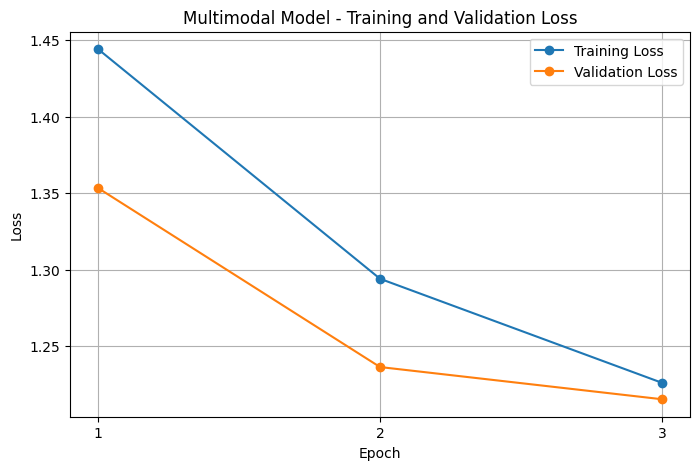

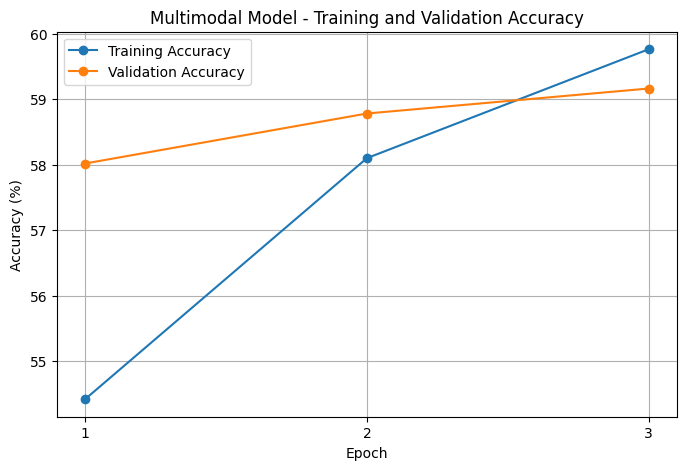

In [87]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

# Training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Multimodal Model - Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()


# Training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Multimodal Model - Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()

In [88]:
from sklearn.metrics import classification_report

multimodal_model.eval()

all_multi_labels = []
all_multi_predictions = []
all_multi_probabilities = []

with torch.no_grad():
    for batch in val_loader:

        clinical_images = batch["clinical"].to(device)
        dermoscopic_images = batch["dermoscopic"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        outputs = multimodal_model(
            clinical_images,
            dermoscopic_images,
            metadata
        )

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        all_multi_labels.extend(labels.cpu().numpy())
        all_multi_predictions.extend(predictions.cpu().numpy())
        all_multi_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy
all_multi_labels = np.array(all_multi_labels)
all_multi_predictions = np.array(all_multi_predictions)
all_multi_probabilities = np.array(all_multi_probabilities)

# Classification report
report = classification_report(
    all_multi_labels,
    all_multi_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
)

print("===== Best Multimodal Model - Validation Report =====")
print(report)

===== Best Multimodal Model - Validation Report =====
              precision    recall  f1-score   support

       AKIEC       0.15      0.07      0.09        46
         BCC       0.66      0.93      0.77       379
     BEN_OTH       0.00      0.00      0.00         6
         BKL       0.26      0.07      0.11        82
          DF       0.00      0.00      0.00         7
         INF       0.00      0.00      0.00         7
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.31      0.27      0.29        67
          NV       0.58      0.65      0.62       112
       SCCKA       0.47      0.20      0.28        71
        VASC       0.00      0.00      0.00         7

    accuracy                           0.59       786
   macro avg       0.22      0.20      0.20       786
weighted avg       0.51      0.59      0.53       786



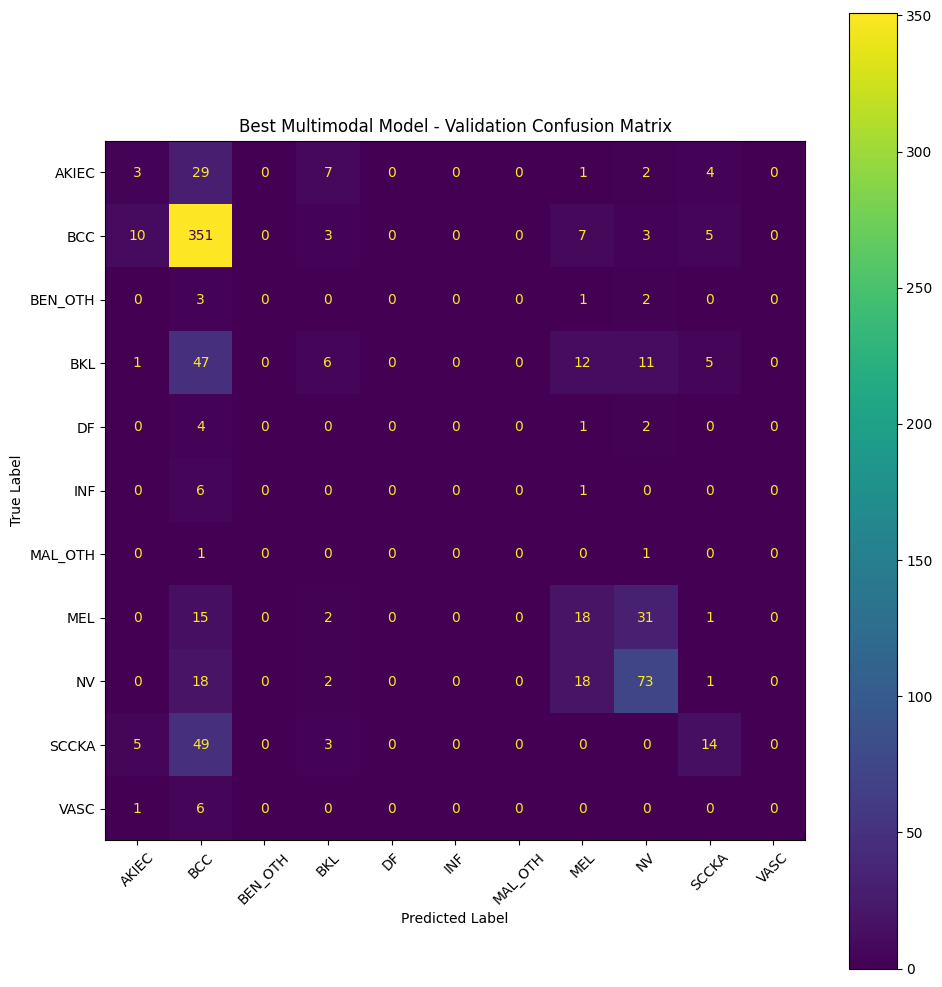

In [89]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_multi = confusion_matrix(
    all_multi_labels,
    all_multi_predictions,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

ax.set_title("Best Multimodal Model - Validation Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [90]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt

# Evaluate only on the test set
multimodal_model.eval()

all_test_labels = []
all_test_predictions = []
all_test_probabilities = []

with torch.no_grad():

    for batch in test_loader:

        clinical_images = batch["clinical"].to(device)
        dermoscopic_images = batch["dermoscopic"].to(device)
        metadata = batch["metadata"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = multimodal_model(
            clinical_images,
            dermoscopic_images,
            metadata
        )

        # Probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predictions
        predictions = torch.argmax(outputs, dim=1)

        all_test_labels.extend(
            labels.cpu().numpy()
        )

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

        all_test_probabilities.extend(
            probabilities.cpu().numpy()
        )


# Convert to NumPy
all_test_labels = np.array(all_test_labels)
all_test_predictions = np.array(all_test_predictions)
all_test_probabilities = np.array(all_test_probabilities)


# =========================
# Calculate Test Metrics
# =========================

test_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

test_precision = precision_score(
    all_test_labels,
    all_test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_test_labels,
    all_test_predictions,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    all_test_labels,
    all_test_predictions,
    average="macro",
    zero_division=0
)

# Multiclass Macro AUC
test_y_true_binary = label_binarize(
    all_test_labels,
    classes=np.arange(NUM_CLASSES)
)

test_auc = roc_auc_score(
    test_y_true_binary,
    all_test_probabilities,
    multi_class="ovr",
    average="macro"
)


# =========================
# Print Results
# =========================

print("==========================================")
print("FINAL TEST RESULTS - MULTIMODAL MODEL")
print("==========================================")

print(
    f"Accuracy : {test_accuracy:.4f} "
    f"({test_accuracy * 100:.2f}%)"
)

print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"AUC      : {test_auc:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


FINAL TEST RESULTS - MULTIMODAL MODEL
Accuracy : 0.5903 (59.03%)
Precision: 0.2240
Recall   : 0.2030
F1-score : 0.1993
AUC      : 0.8139


In [91]:
import pandas as pd

research_results = pd.DataFrame({
    "Model": [
        "Clinical CNN",
        "Dermoscopic CNN",
        "Metadata MLP",
        "Multimodal"
    ],
    "Accuracy": [
        accuracy,
        derm_accuracy,
        meta_accuracy,
        test_accuracy
    ],
    "Precision": [
        precision,
        derm_precision,
        meta_precision,
        test_precision
    ],
    "Recall": [
        recall,
        derm_recall,
        meta_recall,
        test_recall
    ],
    "F1-score": [
        f1,
        derm_f1,
        meta_f1,
        test_f1
    ],
    "AUC": [
        auc,
        derm_auc,
        meta_auc,
        test_auc
    ]
})

# Display as percentages
research_results_display = research_results.copy()

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "AUC"
]:
    research_results_display[column] = (
        research_results_display[column] * 100
    )

print("===== Final Research Results =====")

display(
    research_results_display.style.format({
        "Accuracy": "{:.2f}%",
        "Precision": "{:.2f}%",
        "Recall": "{:.2f}%",
        "F1-score": "{:.2f}%",
        "AUC": "{:.2f}%"
    })
)

===== Final Research Results =====


,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Clinical CNN,57.12%,22.11%,16.79%,14.68%,80.43%
1,Dermoscopic CNN,56.62%,19.36%,17.44%,16.63%,78.22%
2,Metadata MLP,59.67%,14.58%,18.25%,15.24%,72.33%
3,Multimodal,59.03%,22.40%,20.30%,19.93%,81.39%


In [92]:
validation_results = pd.DataFrame({
    "Model": [
        "Clinical CNN",
        "Dermoscopic CNN",
        "Metadata MLP",
        "Multimodal"
    ],
    "Accuracy": [
        accuracy,
        derm_accuracy,
        meta_accuracy,
        multi_accuracy
    ],
    "Precision": [
        precision,
        derm_precision,
        meta_precision,
        multi_precision
    ],
    "Recall": [
        recall,
        derm_recall,
        meta_recall,
        multi_recall
    ],
    "F1-score": [
        f1,
        derm_f1,
        meta_f1,
        multi_f1
    ],
    "AUC": [
        auc,
        derm_auc,
        meta_auc,
        multi_auc
    ]
})

display(
    validation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Clinical CNN,0.5712,0.2211,0.1679,0.1468,0.8043
1,Dermoscopic CNN,0.5662,0.1936,0.1744,0.1663,0.7822
2,Metadata MLP,0.5967,0.1458,0.1825,0.1524,0.7233
3,Multimodal,0.5585,0.1438,0.1690,0.1342,0.7760


# Distribution Shift — Age

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Copy the original metadata
train_shift = train_data.copy()
val_shift = val_data.copy()
test_shift = test_data.copy()

# Age column
age_col = "age_approx_clinical"

# Convert to numeric
train_age = pd.to_numeric(
    train_shift[age_col],
    errors="coerce"
).dropna()

val_age = pd.to_numeric(
    val_shift[age_col],
    errors="coerce"
).dropna()

test_age = pd.to_numeric(
    test_shift[age_col],
    errors="coerce"
).dropna()

print("===== Age Distribution =====")
print(f"Train: {len(train_age)} samples")
print(f"Validation: {len(val_age)} samples")
print(f"Test: {len(test_age)} samples")

print("\nMean age:")
print(f"Train: {train_age.mean():.2f}")
print(f"Validation: {val_age.mean():.2f}")
print(f"Test: {test_age.mean():.2f}")

print("\nMedian age:")
print(f"Train: {train_age.median():.2f}")
print(f"Validation: {val_age.median():.2f}")
print(f"Test: {test_age.median():.2f}")

===== Age Distribution =====
Train: 3668 samples
Validation: 786 samples
Test: 786 samples

Mean age:
Train: 61.31
Validation: 61.67
Test: 61.34

Median age:
Train: 65.00
Validation: 65.00
Test: 65.00


# Visualize Age Shift

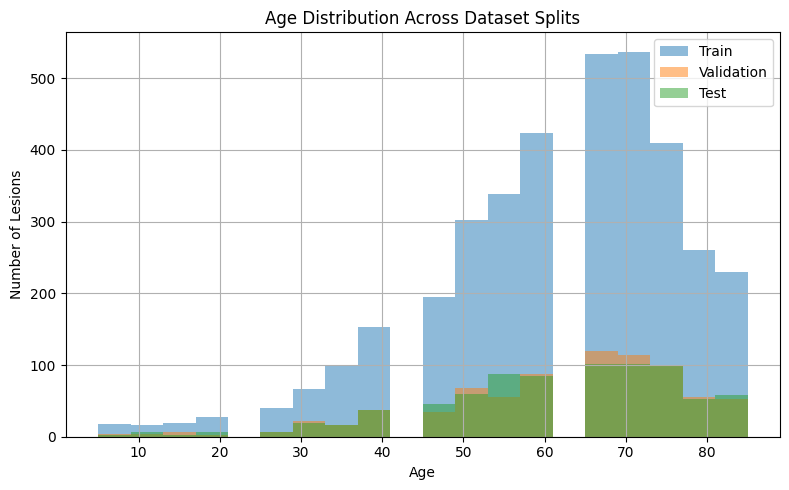

In [95]:
plt.figure(figsize=(8, 5))

plt.hist(
    train_age,
    bins=20,
    alpha=0.5,
    label="Train"
)

plt.hist(
    val_age,
    bins=20,
    alpha=0.5,
    label="Validation"
)

plt.hist(
    test_age,
    bins=20,
    alpha=0.5,
    label="Test"
)

plt.xlabel("Age")
plt.ylabel("Number of Lesions")
plt.title("Age Distribution Across Dataset Splits")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [96]:
from scipy.stats import ks_2samp

# Train vs Validation
ks_train_val = ks_2samp(
    train_age,
    val_age
)

# Train vs Test
ks_train_test = ks_2samp(
    train_age,
    test_age
)

print("===== KS Distribution Shift Test =====")

print("\nTrain vs Validation")
print(f"KS statistic: {ks_train_val.statistic:.4f}")
print(f"P-value: {ks_train_val.pvalue:.6f}")

print("\nTrain vs Test")
print(f"KS statistic: {ks_train_test.statistic:.4f}")
print(f"P-value: {ks_train_test.pvalue:.6f}")

===== KS Distribution Shift Test =====

Train vs Validation
KS statistic: 0.0240
P-value: 0.841473

Train vs Test
KS statistic: 0.0205
P-value: 0.942506


# Categorical Distribution Shift

In [97]:
import numpy as np
from scipy.spatial.distance import jensenshannon

categorical_columns = [
    "sex_clinical",
    "skin_tone_class_clinical",
    "site_clinical"
]

def calculate_js_divergence(train_series, test_series):
    """
    Calculate Jensen-Shannon divergence
    between two categorical distributions.
    """

    # Use categories from both datasets
    categories = sorted(
        set(train_series.dropna().unique())
        | set(test_series.dropna().unique())
    )

    # Calculate normalized frequencies
    train_counts = (
        train_series
        .value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    test_counts = (
        test_series
        .value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    # scipy returns Jensen-Shannon distance
    js_distance = jensenshannon(
        train_counts.values,
        test_counts.values
    )

    # Convert distance to divergence
    js_divergence = js_distance ** 2

    return js_divergence


print("===== Categorical Distribution Shift =====")

js_results = []

for column in categorical_columns:

    train_test_js = calculate_js_divergence(
        train_data[column],
        test_data[column]
    )

    train_val_js = calculate_js_divergence(
        train_data[column],
        val_data[column]
    )

    js_results.append({
        "Feature": column,
        "Train_vs_Validation_JS": train_val_js,
        "Train_vs_Test_JS": train_test_js
    })

js_results_df = pd.DataFrame(js_results)

display(
    js_results_df.style.format({
        "Train_vs_Validation_JS": "{:.6f}",
        "Train_vs_Test_JS": "{:.6f}"
    })
)

===== Categorical Distribution Shift =====


,Feature,Train_vs_Validation_JS,Train_vs_Test_JS
0,sex_clinical,0.000001,0.000143
1,skin_tone_class_clinical,0.001273,0.002783
2,site_clinical,0.002193,0.002054


In [98]:
# Extract deep features from the trained image models

def extract_image_features(model, loader, image_key):
    model.eval()

    features = []

    with torch.no_grad():
        for batch in loader:

            images = batch[image_key].to(device)

            # ResNet18 feature extractor
            x = model.backbone.conv1(images)
            x = model.backbone.bn1(x)
            x = model.backbone.relu(x)
            x = model.backbone.maxpool(x)

            x = model.backbone.layer1(x)
            x = model.backbone.layer2(x)
            x = model.backbone.layer3(x)
            x = model.backbone.layer4(x)

            x = model.backbone.avgpool(x)

            x = torch.flatten(x, 1)

            features.append(x.cpu().numpy())

    return np.concatenate(features, axis=0)


print("Extracting Clinical image features...")

clinical_train_features = extract_image_features(
    clinical_model,
    train_loader,
    "clinical"
)

clinical_val_features = extract_image_features(
    clinical_model,
    val_loader,
    "clinical"
)

clinical_test_features = extract_image_features(
    clinical_model,
    test_loader,
    "clinical"
)

print("Clinical features:")
print("Train:", clinical_train_features.shape)
print("Validation:", clinical_val_features.shape)
print("Test:", clinical_test_features.shape)

Extracting Clinical image features...


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Clinical features:
Train: (3668, 512)
Validation: (786, 512)
Test: (786, 512)


In [99]:
print("Extracting Dermoscopic image features...")

derm_train_features = extract_image_features(
    dermoscopic_model,
    train_loader,
    "dermoscopic"
)

derm_val_features = extract_image_features(
    dermoscopic_model,
    val_loader,
    "dermoscopic"
)

derm_test_features = extract_image_features(
    dermoscopic_model,
    test_loader,
    "dermoscopic"
)

print("Dermoscopic features:")
print("Train:", derm_train_features.shape)
print("Validation:", derm_val_features.shape)
print("Test:", derm_test_features.shape)

Extracting Dermoscopic image features...
Dermoscopic features:
Train: (3668, 512)
Validation: (786, 512)
Test: (786, 512)


In [100]:
from scipy.stats import ks_2samp
import numpy as np
import pandas as pd

def calculate_featurewise_ks(train_features, test_features):
    ks_statistics = []
    p_values = []

    for i in range(train_features.shape[1]):

        statistic, p_value = ks_2samp(
            train_features[:, i],
            test_features[:, i]
        )

        ks_statistics.append(statistic)
        p_values.append(p_value)

    return np.array(ks_statistics), np.array(p_values)


# =========================
# Clinical deep features
# =========================

clinical_ks, clinical_p = calculate_featurewise_ks(
    clinical_train_features,
    clinical_test_features
)


# =========================
# Dermoscopic deep features
# =========================

derm_ks, derm_p = calculate_featurewise_ks(
    derm_train_features,
    derm_test_features
)


# =========================
# Summary
# =========================

image_shift_summary = pd.DataFrame({
    "Modality": [
        "Clinical",
        "Dermoscopic"
    ],
    "Mean_KS": [
        clinical_ks.mean(),
        derm_ks.mean()
    ],
    "Median_KS": [
        np.median(clinical_ks),
        np.median(derm_ks)
    ],
    "Max_KS": [
        clinical_ks.max(),
        derm_ks.max()
    ],
    "Features_KS_gt_0.1": [
        np.sum(clinical_ks > 0.1),
        np.sum(derm_ks > 0.1)
    ],
    "Features_KS_gt_0.2": [
        np.sum(clinical_ks > 0.2),
        np.sum(derm_ks > 0.2)
    ]
})

print("===== Image-Level Distribution Shift =====")

display(
    image_shift_summary.style.format({
        "Mean_KS": "{:.4f}",
        "Median_KS": "{:.4f}",
        "Max_KS": "{:.4f}"
    })
)

===== Image-Level Distribution Shift =====


,Modality,Mean_KS,Median_KS,Max_KS,Features_KS_gt_0.1,Features_KS_gt_0.2
0,Clinical,0.0374,0.0366,0.0762,0,0
1,Dermoscopic,0.0326,0.0313,0.0600,0,0


Clinical PCA explained variance:
PC1: 0.6523
PC2: 0.1187


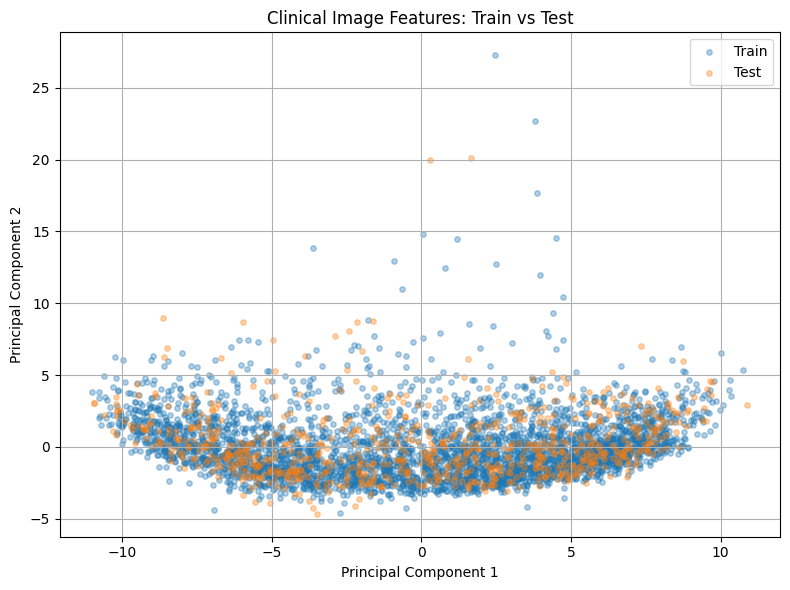

In [101]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Combine train and test features
clinical_combined = np.vstack([
    clinical_train_features,
    clinical_test_features
])

clinical_domain = np.array(
    ["Train"] * len(clinical_train_features)
    + ["Test"] * len(clinical_test_features)
)

# PCA
clinical_pca = PCA(n_components=2)

clinical_pca_features = clinical_pca.fit_transform(
    clinical_combined
)

clinical_pca_df = pd.DataFrame({
    "PC1": clinical_pca_features[:, 0],
    "PC2": clinical_pca_features[:, 1],
    "Domain": clinical_domain
})

print("Clinical PCA explained variance:")
print(
    f"PC1: {clinical_pca.explained_variance_ratio_[0]:.4f}"
)

print(
    f"PC2: {clinical_pca.explained_variance_ratio_[1]:.4f}"
)

plt.figure(figsize=(8, 6))

for domain in ["Train", "Test"]:

    subset = clinical_pca_df[
        clinical_pca_df["Domain"] == domain
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        alpha=0.35,
        s=15,
        label=domain
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Clinical Image Features: Train vs Test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Dermoscopic PCA explained variance:
PC1: 0.6761
PC2: 0.1342


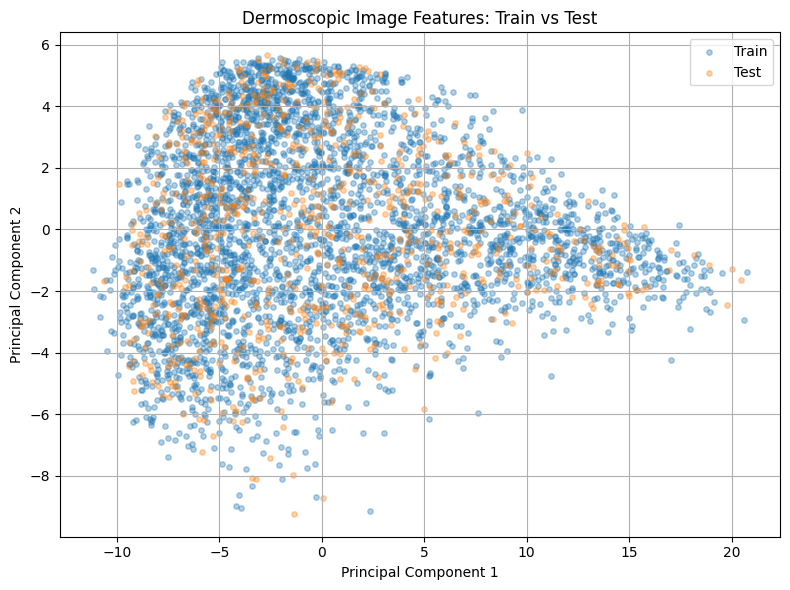

In [102]:
# Combine train and test features
derm_combined = np.vstack([
    derm_train_features,
    derm_test_features
])

derm_domain = np.array(
    ["Train"] * len(derm_train_features)
    + ["Test"] * len(derm_test_features)
)

# PCA
derm_pca = PCA(n_components=2)

derm_pca_features = derm_pca.fit_transform(
    derm_combined
)

derm_pca_df = pd.DataFrame({
    "PC1": derm_pca_features[:, 0],
    "PC2": derm_pca_features[:, 1],
    "Domain": derm_domain
})

print("Dermoscopic PCA explained variance:")
print(
    f"PC1: {derm_pca.explained_variance_ratio_[0]:.4f}"
)

print(
    f"PC2: {derm_pca.explained_variance_ratio_[1]:.4f}"
)

plt.figure(figsize=(8, 6))

for domain in ["Train", "Test"]:

    subset = derm_pca_df[
        derm_pca_df["Domain"] == domain
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        alpha=0.35,
        s=15,
        label=domain
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Dermoscopic Image Features: Train vs Test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()